<a href="https://colab.research.google.com/github/MarcinPlodzien/deep-learning-for-scientific-discovery/blob/main/notebooks/lecture-06/galaxy-beta-vae.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"></a>

# Interpretable latent factors

*Deep Learning for Scientific Discovery, Jagiellonian University. Author: Marcin Płodzień.*

A classifier trained on galaxy images may reach a good test accuracy, but the number alone does not tell us what in the image the decision rests on. Two kinds of interpretability are useful here, and it helps to keep them apart. The first concerns the *data*: along which few directions do the images vary? A disentangled latent space provides such directions, a handful of approximately independent coordinates, each changing one property of the image (its size, its elongation, its colour). The second concerns a *trained classifier*: which of these properties does its decision depend on? Connecting the two answers the second question in the language of the first.

The tool for the data is the β-VAE of [Higgins et al. (ICLR 2017)](https://openreview.net/forum?id=Sy2fzU9gl), a variational autoencoder (VAE) whose loss puts a weight $\beta\ge1$ on the Kullback–Leibler (KL) term,
$$
\mathcal L_\beta(\mathbf x)=\mathbb E_{q_\phi(\mathbf z|\mathbf x)}\big[-\log p_\theta(\mathbf x\,|\,\mathbf z)\big]+\beta\,\mathrm{KL}\big(q_\phi(\mathbf z\,|\,\mathbf x)\,\|\,p(\mathbf z)\big),\qquad p(\mathbf z)=\mathcal N(0,I). \tag{1}
$$
The encoder $q_\phi(\mathbf z|\mathbf x)=\mathcal N\big(\boldsymbol\mu(\mathbf x),\operatorname{diag}\boldsymbol\sigma^2(\mathbf x)\big)$ maps an image $\mathbf x$ to a Gaussian cloud in a space of $d$ latent coordinates, the decoder $G$ maps a latent vector $\mathbf z$ back to an image and defines $p_\theta(\mathbf x|\mathbf z)$. For $\beta=1$ this is the ordinary VAE of the lecture. A larger $\beta$ makes every nat of information stored in $\mathbf z$ more expensive; since the prior has independent coordinates, the network is pushed to keep only the main causes of variation and to store them in separate coordinates.

The tool for the classifier is a *counterfactual* in the latent space. We encode a real galaxy, $\boldsymbol\mu=\boldsymbol\mu(\mathbf x)$, move one coordinate by $\delta$, decode $\mathbf x'(\delta)=G(\boldsymbol\mu+\delta\,\mathbf e_k)$, where $\mathbf e_k$ is the unit vector along coordinate $k$, and give $\mathbf x'(\delta)$ to the classifier. The change of the predicted class probabilities as a function of $\delta$ measures how sensitive the classifier is to factor $k$, and a value of $\delta$ at which the predicted class changes is a counterfactual explanation: "had this property of the galaxy been different by this much, the network would have called it something else". This complements the class activation maps (CAM) of Lecture 3, which highlight *where* in the image the evidence lies; the latent counterfactual asks *which property* of the image the decision depends on.

The data are colour images of galaxies from the DESI Legacy Imaging Surveys, labelled by Galaxy Zoo volunteers. Since there is no ground truth for what the "factors" of a galaxy image are, we judge the latent coordinates against morphology proxies measured directly from each image. The companion notebook `notebook_2026-10-27-interpretability_beta_vae_spectra_spins.ipynb` applies the same β-VAE to simulated spectra, where the true factors are known and disentanglement can be scored, and to Ising and XY spin configurations.

All computations run on the central processing unit (CPU) with fixed random seeds. Trained weights are stored in `results/` and reloaded when present, so a second run takes a few minutes.

In [1]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = ""          # CPU only
import json, time, subprocess, sys, urllib.request
import numpy as np
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
try:
    from torchinfo import summary
except ImportError:                              # e.g. in Google Colab
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "torchinfo"], check=True)
    from torchinfo import summary
torch.set_num_threads(8)
t_start = time.time()

import os
OUT = "figures"; os.makedirs(OUT, exist_ok=True); os.makedirs(OUT, exist_ok=True)       # figures used on the slides
RES = "results"; os.makedirs(RES, exist_ok=True)                 # weights and numbers
DATA = "data"; os.makedirs(DATA, exist_ok=True)
blue, orange, navy, gray = "#005CA7", "#EB6709", "#0A2F5C", "#5A6270"
nums = {}                                                        # numbers quoted on the slides
def clean(ax):
    for s in ["top", "right"]: ax.spines[s].set_visible(False)
def seed(k):
    torch.manual_seed(k); return np.random.default_rng(k)
plt.rcParams.update({"font.size": 15, "axes.titlesize": 16, "axes.labelsize": 15, "xtick.labelsize": 13, "ytick.labelsize": 13,
                     "legend.fontsize": 13, "figure.titlesize": 17, "figure.facecolor": "white", "savefig.facecolor": "white"})
print("PyTorch", torch.__version__, "| threads", torch.get_num_threads())

PyTorch 2.9.0+cpu | threads 8


## Galaxy10 DECaLS

The images come from the DESI Legacy Imaging Surveys ([Dey et al., AJ 157, 168, 2019](https://doi.org/10.3847/1538-3881/ab089d)), whose DECaLS part (Dark Energy Camera Legacy Survey) imaged the sky with the Dark Energy Camera at the 4-m Blanco telescope in three optical filters, the $g$ (green, about 480 nm), $r$ (red, about 640 nm) and $z$ (near-infrared, about 920 nm) bands. The morphology labels come from Galaxy Zoo DECaLS ([Walmsley et al., MNRAS 509, 3966, 2022](https://doi.org/10.1093/mnras/stab2093)), in which volunteers answered a tree of questions about each galaxy ("smooth or featured?", "edge-on?", "bar?", "how tightly wound are the spiral arms?"). [Galaxy10 DECaLS](https://github.com/henrysky/Galaxy10) by Henry Leung and Jo Bovy turns the volunteer votes into ten classes for 17 736 galaxies whose votes are clear enough; it is distributed through [astroNN](https://astronn.readthedocs.io/en/latest/galaxy10.html) and on Zenodo ([doi:10.5281/zenodo.10845026](https://doi.org/10.5281/zenodo.10845026)) under the Creative Commons Attribution 4.0 (CC BY 4.0) licence, which allows reuse with attribution.

One sample $\mathbf x_i$ is a colour image of $256\times256$ pixels centred on the galaxy, with a pixel scale of $0.262$ arcseconds (arcsec), so that the image covers $67''\times67''$ of the sky. Its three channels are made from the $g$, $r$ and $z$ exposures and stored as 8-bit integers from 0 to 255; they are a display composite with a non-linear brightness stretch, not calibrated fluxes. The redder band is shown in the red channel, so old stellar populations (elliptical galaxies, bulges) appear yellow-red and star-forming spiral arms appear blue. Each image comes with one class label $y_i\in\{0,\dots,9\}$, and with the sky position and redshift of the galaxy, which we do not use.

To keep the computation on a CPU, we cut out the central $128\times128$ pixels ($33.5''\times33.5''$), which contain almost the whole galaxy in nearly every image, and average blocks of $2\times2$ pixels. The result is a $64\times64\times3$ image with $0.524''$ per pixel: the shape, orientation, colour and spiral arms of the galaxies survive, while the 16-fold reduction of the number of pixels makes the training of several networks possible in minutes. On the first run the code downloads the full file (2.7 GB) from Zenodo and builds the 64-pixel version; later runs load the 64-pixel file (185 MB) from disk.

In [2]:
G64 = f"{DATA}/galaxy10_decals_64.npz"
H5 = f"{DATA}/Galaxy10_DECals.h5"
H5_URL = "https://zenodo.org/records/10845026/files/Galaxy10_DECals.h5?download=1"     # 2.7 GB

def downsample_galaxy10(h5_path, out_path, chunk=500):
    """Central 128 x 128 crop of every 256 x 256 image, averaged over 2 x 2 blocks -> 64 x 64 x 3 uint8."""
    import h5py
    with h5py.File(h5_path, "r") as f:
        n = len(f["ans"]); imgs = np.empty((n, 64, 64, 3), np.uint8)
        for i in range(0, n, chunk):
            x = f["images"][i:i + chunk, 64:192, 64:192].astype(np.float32)          # central 128 x 128 pixels
            imgs[i:i + chunk] = np.round(x.reshape(-1, 64, 2, 64, 2, 3).mean((2, 4))).astype(np.uint8)
        np.savez_compressed(out_path, images=imgs, labels=f["ans"][:], redshift=f["redshift"][:],
                            ra=f["ra"][:], dec=f["dec"][:], pxscale=f["pxscale"][:])

if not os.path.exists(G64):                                     # first run: the full data set from Zenodo, then downsample
    if not os.path.exists(H5):
        print("downloading", H5_URL); urllib.request.urlretrieve(H5_URL, H5)
    t0 = time.time(); downsample_galaxy10(H5, G64); print(f"downsampled in {time.time() - t0:.0f} s")
g = np.load(G64)
G_img, G_lab, G_z = g["images"], g["labels"].astype(np.int64), g["redshift"]
print("images:", G_img.shape, G_img.dtype, f"| file size {os.path.getsize(G64) / 1e6:.0f} MB")

images: (17736, 64, 64, 3) uint8 | file size 185 MB


0  disturbed                  1081
1  merging                    1853
2  round smooth               2645
3  in-between round smooth    2027
4  cigar-shaped smooth         334
5  barred spiral              2043
6  unbarred tight spiral      1829
7  unbarred loose spiral      2628
8  edge-on without bulge      1423
9  edge-on with bulge         1873
training images 15076, test images 2660


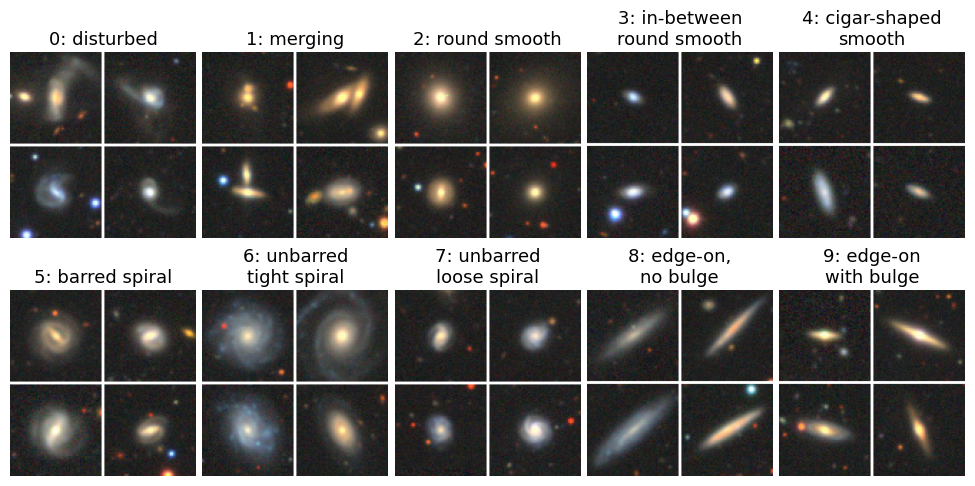

In [3]:
CLASSES = ["disturbed", "merging", "round smooth", "in-between round smooth", "cigar-shaped smooth", "barred spiral",
           "unbarred tight spiral", "unbarred loose spiral", "edge-on without bulge", "edge-on with bulge"]
counts = np.bincount(G_lab, minlength=10)
for k in range(10): print(f"{k}  {CLASSES[k]:25s} {counts[k]:5d}")
rng = seed(0)
perm = rng.permutation(len(G_lab)); n_test = 2660
te_idx, tr_idx = np.sort(perm[:n_test]), np.sort(perm[n_test:])
print(f"training images {len(tr_idx)}, test images {len(te_idx)}")
nums["galaxy_counts"] = counts.tolist(); nums["galaxy_n_train"], nums["galaxy_n_test"] = len(tr_idx), len(te_idx)

fig, axs = plt.subplots(2, 5, figsize=(10, 5.4))
SHORT = ["disturbed", "merging", "round smooth", "in-between\nround smooth", "cigar-shaped\nsmooth", "barred spiral",
         "unbarred\ntight spiral", "unbarred\nloose spiral", "edge-on,\nno bulge", "edge-on\nwith bulge"]
for k, a in enumerate(axs.ravel()):
    ex = G_img[tr_idx[np.flatnonzero(G_lab[tr_idx] == k)[:4]]]
    mosaic = np.ones((130, 130, 3), np.uint8) * 255
    for q in range(4): mosaic[(q // 2) * 66:(q // 2) * 66 + 64, (q % 2) * 66:(q % 2) * 66 + 64] = ex[q]
    a.imshow(mosaic); a.set_xticks([]); a.set_yticks([]); [sp.set_visible(False) for sp in a.spines.values()]
    a.set_title(f"{k}: {SHORT[k]}", fontsize=13)
plt.tight_layout(h_pad=0.4, w_pad=0.3); plt.savefig(f"{OUT}/interp_galaxy_examples.png", dpi=200, bbox_inches="tight"); plt.show()

The ten classes are far from balanced: there are 2645 round smooth galaxies but only 334 cigar-shaped ones. Several classes differ in a single property that a volunteer judges by eye: round, in-between and cigar-shaped smooth galaxies differ in elongation; tight and loose spirals in how the arms are wound; the two edge-on classes in the presence of a central bulge. Others, disturbed and merging galaxies, are defined by irregular structure that has no single direction of variation. We hold out 2660 randomly chosen images (15%) as a test set, on which all latent coordinates and proxies below are evaluated.

## Morphology proxies

To give the latent coordinates a meaning, we need properties that can be measured from each image without any label. An astronomer would fit a light profile; we use simple estimates from the pixels. The sky level and its noise are taken from a 4-pixel frame around the image, as the median brightness $b_{\rm sky}$ and the median absolute deviation, scaled by 1.4826 so that it equals the standard deviation $\sigma_{\rm sky}$ for Gaussian noise. A pixel belongs to a source if its brightness, the mean of the three channels, exceeds $b_{\rm sky}+3\sigma_{\rm sky}$; the galaxy mask is the connected region of such pixels that contains the brightest pixel near the centre, with holes filled. Stars and neighbouring galaxies form separate regions and are excluded. From the sky-subtracted brightness $f(\mathbf r)$ inside the mask we compute:

- the apparent size, the area of the mask in arcsec$^2$;
- the total brightness $\sum_{\mathbf r}f(\mathbf r)$ (in units of the 8-bit scale), which is not a calibrated flux because of the display stretch;
- the axis ratio from the eigenvalues $\lambda_{\min}\le\lambda_{\max}$ of the matrix of second moments,
$$M_{ij}=\frac{\sum_{\mathbf r}f(\mathbf r)\,(r_i-\bar r_i)(r_j-\bar r_j)}{\sum_{\mathbf r}f(\mathbf r)},\qquad \frac ba=\sqrt{\frac{\lambda_{\min}}{\lambda_{\max}}}, \tag{2}$$
which is 1 for a round image and small for a thin disk seen edge-on;
- the position angle $\vartheta$ of the major axis,
$$\tan2\vartheta=\frac{2M_{xy}}{M_{xx}-M_{yy}}; \tag{3}$$
since $\vartheta$ and $\vartheta+\pi$ describe the same orientation, we use $\cos2\vartheta$ and $\sin2\vartheta$;
- the two components of the ellipticity, which combine elongation and orientation and vanish for a round image,
$$\varepsilon=\frac{1-b/a}{1+b/a},\qquad e_1=\varepsilon\cos2\vartheta,\qquad e_2=\varepsilon\sin2\vartheta ; \tag{4}$$
- a colour index $(R-B)/(R+B)$ from the sky-subtracted sums of the red and blue channels, a proxy for the $g-z$ colour: positive for red, old stellar populations and negative for blue, star-forming ones;
- the concentration $r_{90}/r_{50}$, the ratio of the radii that contain 90% and 50% of the brightness; centrally concentrated (bulge-dominated) galaxies have larger values;
- the half-light radius $r_{50}$ in arcsec, and the offset of the brightness centre from the image centre.

proxies of 2660 test images in 3 s; no galaxy found in 0 images
class                           size brightness        r50        b/a      cos2θ      sin2θ         e1         e2     colour          C     offset
disturbed                     218.01     252.13       4.88       0.63       0.01       0.02       0.00       0.00      -0.11       1.73       0.63
merging                       252.47     288.63       5.54       0.58       0.12      -0.15       0.02      -0.03       0.16       1.68       2.79
round smooth                  190.42     189.30       4.13       0.92       0.02       0.01       0.00       0.00       0.19       1.67       0.18
in-between round smooth       145.80     168.33       3.63       0.65       0.12       0.21       0.02       0.04       0.13       1.75       0.19
cigar-shaped smooth           140.03     174.47       3.83       0.43      -0.34      -0.10      -0.12      -0.04       0.04       1.91       0.33
barred spiral                 322.90     375.90       

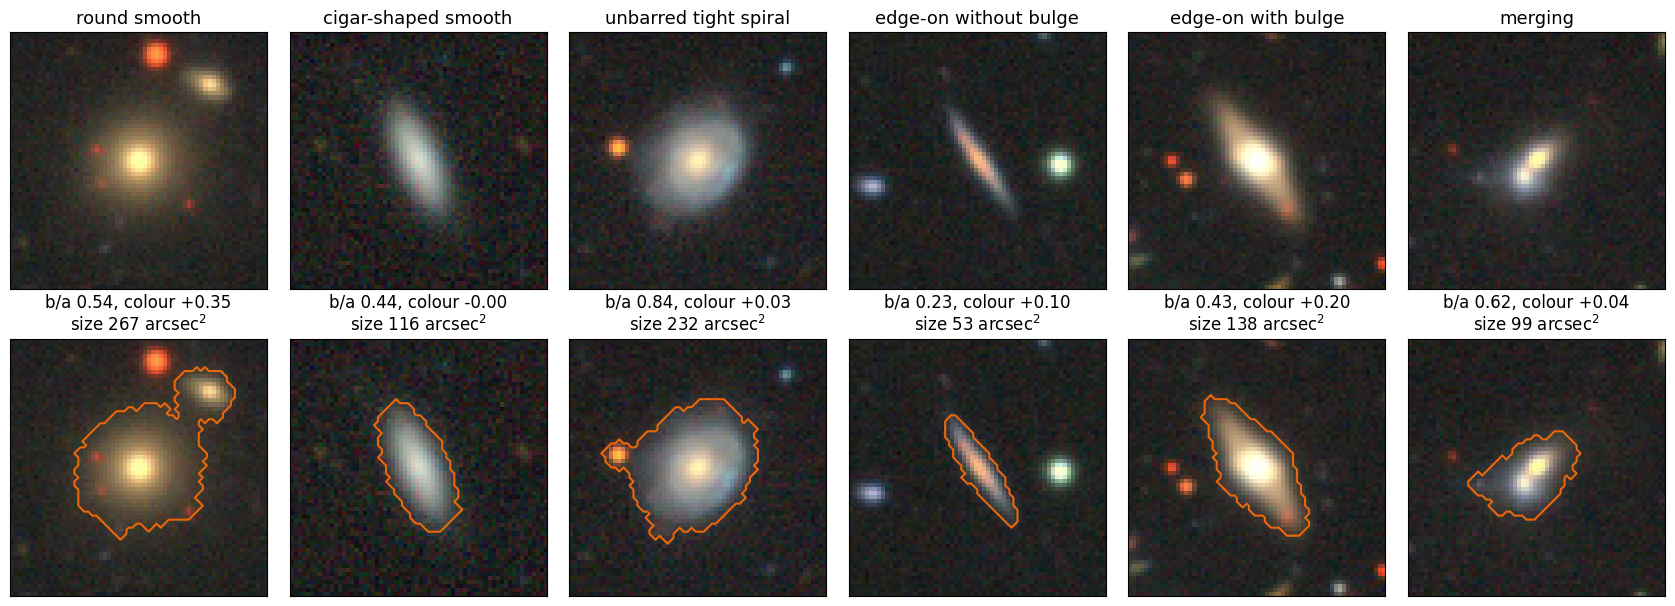

In [4]:
from scipy import ndimage as ndi
PIX = 0.262 * 2                                                 # arcsec per pixel after the 2 x 2 averaging
def galaxy_proxies(img):
    """Morphology proxies of one 64 x 64 x 3 uint8 image; returns a dict and the galaxy mask."""
    x = img.astype(np.float32)
    lum = x.mean(-1)                                            # brightness of each pixel, mean of the three channels
    border = np.concatenate([lum[:4].ravel(), lum[-4:].ravel(), lum[:, :4].ravel(), lum[:, -4:].ravel()])
    bg = np.median(border); noise = 1.4826 * np.median(np.abs(border - bg)) + 1.0   # robust sky level and noise
    above = ndi.binary_opening(lum > bg + 3 * noise)            # pixels clearly above the sky
    lab, n = ndi.label(above)
    if n == 0: return None, np.zeros_like(above)
    # the galaxy: the component that contains the brightest pixel within 8 pixels of the centre
    c = lum[24:40, 24:40]; iy, ix = np.unravel_index(np.argmax(c), c.shape)
    k = lab[24 + iy, 24 + ix]
    if k == 0: return None, np.zeros_like(above)
    mask = ndi.binary_fill_holes(lab == k)
    f = np.clip(lum - bg, 0, None) * mask                       # sky-subtracted brightness inside the mask
    F = f.sum()
    yy, xx = np.indices(lum.shape)
    cy, cx = (f * yy).sum() / F, (f * xx).sum() / F             # flux-weighted centre
    myy, mxx, mxy = (f * (yy - cy) ** 2).sum() / F, (f * (xx - cx) ** 2).sum() / F, (f * (yy - cy) * (xx - cx)).sum() / F
    lam = np.linalg.eigvalsh(np.array([[mxx, mxy], [mxy, myy]]))   # lam[0] <= lam[1]
    q = np.sqrt(lam[0] / lam[1])                                # axis ratio b/a
    pa = 0.5 * np.arctan2(2 * mxy, mxx - myy)                   # orientation of the major axis
    r = np.hypot(yy - cy, xx - cx)[mask]; fr = f[mask]; o = np.argsort(r); cum = np.cumsum(fr[o]) / F
    r50, r90 = r[o][np.searchsorted(cum, 0.5)], r[o][np.searchsorted(cum, 0.9)]
    sky = np.median(np.stack([x[:4].reshape(-1, 3), x[-4:].reshape(-1, 3)]).reshape(-1, 3), 0)
    rgb = np.clip(x - sky, 0, None)[mask].sum(0)                # sky-subtracted sum of each channel in the mask
    eps = (1 - q) / (1 + q)                                     # ellipticity, 0 for a round image
    return dict(area=mask.sum() * PIX ** 2, flux=F / 255, axis_ratio=q, cos2pa=np.cos(2 * pa), sin2pa=np.sin(2 * pa),
                e1=eps * np.cos(2 * pa), e2=eps * np.sin(2 * pa),
                colour=(rgb[0] - rgb[2]) / (rgb[0] + rgb[2] + 1e-9), concentration=r90 / max(r50, 0.5),
                r50=r50 * PIX, offset=np.hypot(cy - 31.5, cx - 31.5) * PIX), mask

PROXIES = ["area", "flux", "r50", "axis_ratio", "cos2pa", "sin2pa", "e1", "e2", "colour", "concentration", "offset"]
PROXY_LABELS = ["size", "brightness", "$r_{50}$", "axis ratio $b/a$", r"$\cos2\vartheta$", r"$\sin2\vartheta$",
                "ellipticity $e_1$", "ellipticity $e_2$", "colour $c$", "concentration $C$", "offset"]
SHORTP = dict(area="size", flux="brightness", r50="r50", axis_ratio="b/a", cos2pa="cos2θ", sin2pa="sin2θ", e1="e1", e2="e2",
              colour="colour", concentration="C", offset="offset")
t0 = time.time()
P_list = [galaxy_proxies(G_img[i])[0] for i in te_idx]
ok = np.array([p is not None for p in P_list])
P_te = np.array([[p[k] for k in PROXIES] if p is not None else [np.nan] * len(PROXIES) for p in P_list])
print(f"proxies of {len(te_idx)} test images in {time.time() - t0:.0f} s; no galaxy found in {(~ok).sum()} images")
print(f"{'class':25s}" + "".join(f"{SHORTP[k]:>11s}" for k in PROXIES))
for k in range(10):
    m = ok & (G_lab[te_idx] == k)
    print(f"{CLASSES[k]:25s}" + "".join(f"{np.median(P_te[m, j]):11.2f}" for j in range(len(PROXIES))))
nums["proxy_median_per_class"] = {CLASSES[k]: np.round(np.median(P_te[ok & (G_lab[te_idx] == k)], 0), 3).tolist() for k in range(10)}

fig, axs = plt.subplots(2, 6, figsize=(17, 6.3))
for j, k in enumerate([2, 4, 6, 8, 9, 1]):
    i = te_idx[np.flatnonzero(G_lab[te_idx] == k)[1]]
    p, m = galaxy_proxies(G_img[i])
    axs[0, j].imshow(G_img[i]); axs[0, j].set_title(CLASSES[k], fontsize=13)
    axs[1, j].imshow(G_img[i]); axs[1, j].contour(m, levels=[0.5], colors=[orange], linewidths=1.5)
    axs[1, j].set_title(f"b/a {p['axis_ratio']:.2f}, colour {p['colour']:+.2f}\nsize {p['area']:.0f} arcsec$^2$", fontsize=12)
for a in axs.ravel(): a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()

The proxies separate the classes the way an astronomer would expect. Round smooth galaxies have the largest axis ratio, 0.92 in the median, cigar-shaped ones 0.43 and edge-on disks the smallest, 0.23 without and 0.33 with a bulge. Spirals are the largest and brightest objects in the images (median sizes 270 to 350 arcsec²), smooth galaxies the smallest; round smooth galaxies and edge-on disks with a bulge are the reddest (colour index 0.19 and 0.22), while disturbed galaxies and loose spirals are the bluest. Edge-on disks with a bulge have the highest concentration, 2.13, and merging systems the largest offset of the brightness centre, 2.8 arcsec, because two objects share the light. The median position-angle terms are small for most classes, as expected: the orientation of a galaxy on the sky is random.

## β-VAE for galaxy images

The encoder is a convolutional network of the type used for $64\times64$ images by [Burgess et al. (2018)](https://arxiv.org/abs/1804.03599): four convolutions with $4\times4$ kernels and stride 2 halve the image four times, $64\to32\to16\to8\to4$ pixels, with 32, 32, 64 and 64 channels and the rectified linear unit $\mathrm{ReLU}(u)=\max(0,u)$ after each; the $4\times4\times64=1024$ numbers are flattened and passed through a dense layer of 256 units to $\boldsymbol\mu$ and $\log\boldsymbol\sigma^2$, each of length $d=10$. The decoder mirrors the encoder with transposed convolutions, which double the image size at every step, and ends with a sigmoid, so that $G(\mathbf z)$ is an image with values in $[0,1]$.

For the decoder distribution we choose a Gaussian, with pixel values scaled to the interval from 0 to 1,
$$p_\theta(\mathbf x|\mathbf z)=\mathcal N\big(\mathbf x;G(\mathbf z),\sigma_x^2I\big),\qquad -\log p_\theta(\mathbf x|\mathbf z)=\frac{\|\mathbf x-G(\mathbf z)\|^2}{2\sigma_x^2}+\text{const}. \tag{5}$$ The pixel values of a galaxy image are continuous intensities rather than probabilities of a binary event, so the Bernoulli decoder of the digit examples has no natural meaning here. The width $\sigma_x$ sets the price of a reconstruction error relative to the KL term and therefore acts together with $\beta$: we fix $\sigma_x=0.1$, a tenth of the full intensity range, and vary $\beta$.

The function `draw_network` sketches the architecture. Each image-shaped tensor is drawn as a box whose height grows with its size in pixels and whose depth grows with the number of channels; vectors are drawn as columns of units.

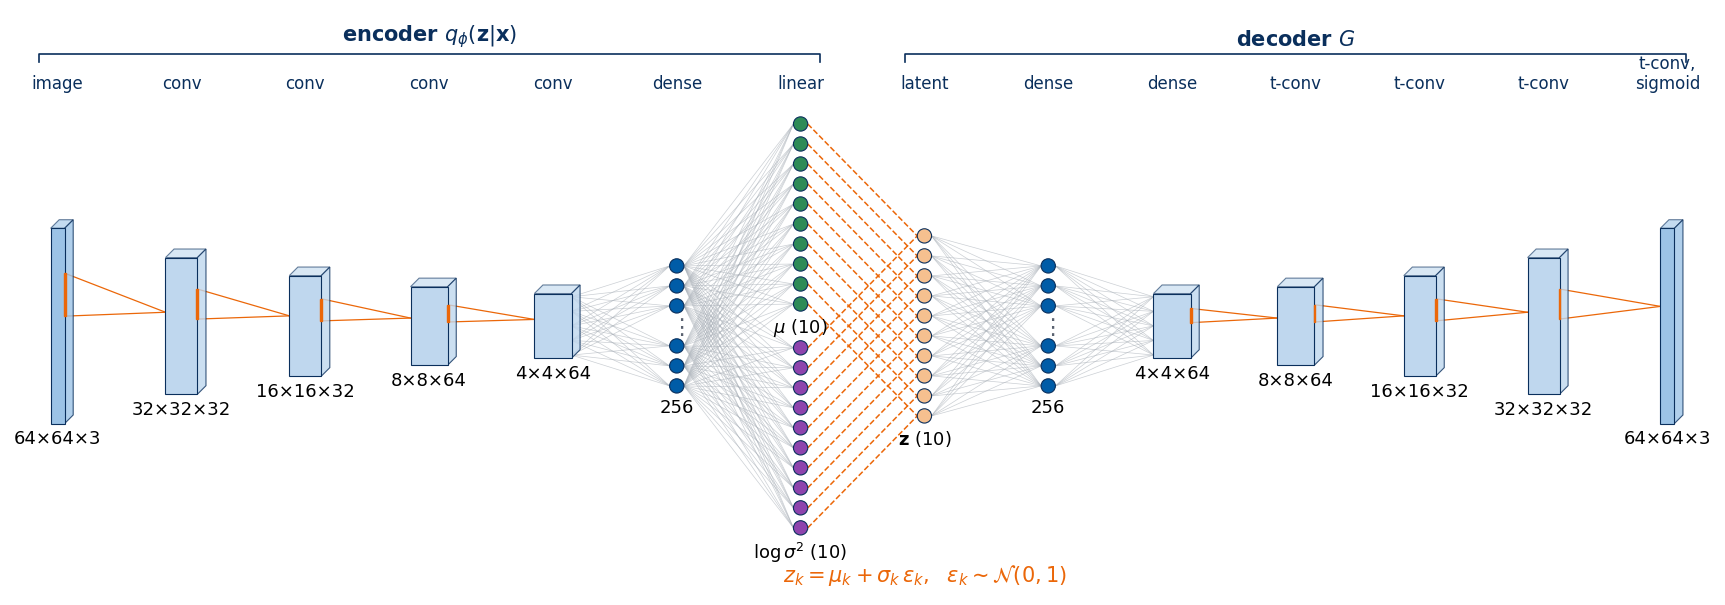

In [5]:
def draw_network(ax, layers, gaps, titles=None, max_full=8, n_edge=3, dx=2.6, dy=0.42, r=0.15, edge_colour="#A9B0B8",
                 groups=None, label_size=13):
    """Sketch an encoder-decoder network as a row of layers connected by edges.

    ax          : matplotlib axes to draw on
    layers      : list of layers from left to right; each layer is a list of blocks, and each block is a dict with
                  kind ("map" for an image-shaped tensor or "vector" for a list of units), colour, label (text below the
                  block) and either side, channels (for a map: height in pixels and number of channels) or size (for a
                  vector: number of units)
    gaps        : one entry per pair of consecutive layers: "conv" (a 4 x 4 kernel on the left map produces one pixel of
                  the right map), "dense" (every unit, or every number of a flattened map, connected to every unit),
                  "sample" (unit k of every block connected to unit k of z, dashed: z = mu + sigma * eps)
    titles      : optional list of titles (the operation producing the layer) written above the layers
    max_full    : vectors with at most this many units are drawn completely
    n_edge      : larger vectors show their first n_edge and last n_edge units around a vertical ellipsis
    dx, dy      : horizontal distance between layers and vertical distance between the units of a vector
    r           : radius of a unit
    edge_colour : colour of the dense connections
    groups      : optional list of (first layer, last layer, text) brackets drawn above the network
    label_size  : font size of the labels and titles
    """
    geo, top, bottom = [], 0.0, 0.0                     # geo[l][b]: drawing information of block b of layer l
    for l, layer in enumerate(layers):
        x0 = l * dx; blocks = []
        # vertical extent of every block, then stack the blocks of a layer around y = 0
        heights = []
        for blk in layer:
            if blk["kind"] == "map": heights.append(0.9 + 3.2 * (blk["side"] / 64) ** 0.7)
            else:
                n_show = blk["size"] if blk["size"] <= max_full else 2 * n_edge + 1
                heights.append(n_show * dy)
        y = (sum(heights) + 0.5 * (len(layer) - 1)) / 2
        for blk, h in zip(layer, heights):
            yc = y - h / 2; y -= h + 0.5
            if blk["kind"] == "map":
                depth = 0.12 + 0.11 * np.log2(blk["channels"])             # depth grows with the number of channels
                off = 0.18                                                  # offset of the back face (perspective)
                xs, ys = x0 - depth / 2, yc - h / 2
                ax.add_patch(plt.Polygon([[xs, ys + h], [xs + off, ys + h + off], [xs + depth + off, ys + h + off], [xs + depth, ys + h]],
                                         facecolor=blk["colour"], edgecolor=navy, lw=0.8, alpha=0.6, zorder=2))
                ax.add_patch(plt.Polygon([[xs + depth, ys], [xs + depth + off, ys + off], [xs + depth + off, ys + h + off], [xs + depth, ys + h]],
                                         facecolor=blk["colour"], edgecolor=navy, lw=0.8, alpha=0.8, zorder=2))
                ax.add_patch(plt.Rectangle((xs, ys), depth, h, facecolor=blk["colour"], edgecolor=navy, lw=0.8, zorder=3))
                blocks.append(dict(kind="map", x0=xs, x1=xs + depth, y0=ys, y1=ys + h))
                ax.text(x0, ys - 0.12, blk["label"], ha="center", va="top", fontsize=label_size)
            else:
                n = blk["size"]
                idx = list(range(n)) if n <= max_full else list(range(n_edge)) + ["dots"] + list(range(n - n_edge, n))
                ys_ = yc + (np.arange(len(idx))[::-1] - (len(idx) - 1) / 2) * dy
                units = []
                for k, yy in zip(idx, ys_):
                    if k == "dots": ax.text(x0, yy, r"$\vdots$", ha="center", va="center", fontsize=16, color=gray)
                    else:
                        ax.add_patch(plt.Circle((x0, yy), r, facecolor=blk["colour"], edgecolor=navy, lw=0.8, zorder=3)); units.append((x0, yy, k))
                blocks.append(dict(kind="vector", units=units))
                ax.text(x0, ys_.min() - r - 0.1, blk["label"], ha="center", va="top", fontsize=label_size)
            top, bottom = max(top, yc + h / 2), min(bottom, yc - h / 2)
        geo.append(blocks)
    def anchors(b, side):                                # points on the right (side = 1) or left (side = 0) edge of a block
        if b["kind"] == "vector": return [(x + (r if side else -r), y) for x, y, _ in b["units"]]
        x = b["x1"] if side else b["x0"]
        return [(x, b["y0"] + t * (b["y1"] - b["y0"])) for t in np.linspace(0.05, 0.95, 5)]
    for l, kind in enumerate(gaps):
        for b1 in geo[l]:
            for b2 in geo[l + 1]:
                if kind == "conv":                       # a kernel patch on the left map and its output pixel
                    h1 = b1["y1"] - b1["y0"]; ky = b1["y0"] + 0.55 * h1; ks = 0.22 * h1
                    ax.add_patch(plt.Rectangle((b1["x1"] - 0.02, ky), 0.04, ks, color=orange, zorder=4))
                    py = b2["y0"] + 0.6 * (b2["y1"] - b2["y0"])
                    for yy in (ky, ky + ks): ax.plot([b1["x1"], b2["x0"]], [yy, py], color=orange, lw=0.9, zorder=1)
                elif kind == "dense":
                    for (x1, y1) in anchors(b1, 1):
                        for (x2, y2) in anchors(b2, 0): ax.plot([x1, x2], [y1, y2], color=edge_colour, lw=0.5, alpha=0.6, zorder=1)
                elif kind == "sample":
                    for (x1, y1, k1) in b1["units"]:
                        for (x2, y2, k2) in b2["units"]:
                            if k1 == k2: ax.plot([x1 + r, x2 - r], [y1, y2], color=orange, lw=1.1, ls="--", zorder=1)
    if titles:
        for l, t in enumerate(titles): ax.text(l * dx, top + 0.45, t, ha="center", va="bottom", fontsize=label_size - 1, color=navy)
    for (l1, l2, text) in (groups or []):                # encoder / decoder brackets
        yb = top + 1.25
        ax.plot([l1 * dx - 0.4, l1 * dx - 0.4, l2 * dx + 0.4, l2 * dx + 0.4], [yb - 0.15, yb, yb, yb - 0.15], color=navy, lw=1.2)
        ax.text((l1 + l2) * dx / 2, yb + 0.1, text, ha="center", va="bottom", fontsize=15, color=navy, weight="bold")
    ax.set_aspect("equal"); ax.axis("off"); ax.set_xlim(-1.0, (len(layers) - 1) * dx + 1.0); ax.set_ylim(bottom - 1.2, top + 2.2)

c_img, c_map, c_h, c_mu, c_lv, c_z = "#9CC3E6", "#BFD7EE", blue, "#2E8B57", "#8E44AD", "#F6C08F"
M = lambda s, c, lab: dict(kind="map", side=s, channels=c, colour=c_img if c == 3 else c_map, label=lab)
Vv = lambda n, col, lab: dict(kind="vector", size=n, colour=col, label=lab)
layers = [[M(64, 3, "64×64×3")], [M(32, 32, "32×32×32")], [M(16, 32, "16×16×32")], [M(8, 64, "8×8×64")], [M(4, 64, "4×4×64")],
          [Vv(256, c_h, "256")], [Vv(10, c_mu, r"$\mu$ (10)"), Vv(10, c_lv, r"$\log\sigma^2$ (10)")], [Vv(10, c_z, r"$\mathbf{z}$ (10)")],
          [Vv(256, c_h, "256")], [M(4, 64, "4×4×64")], [M(8, 64, "8×8×64")], [M(16, 32, "16×16×32")], [M(32, 32, "32×32×32")], [M(64, 3, "64×64×3")]]
gaps = ["conv", "conv", "conv", "conv", "dense", "dense", "sample", "dense", "dense", "conv", "conv", "conv", "conv"]
titles = ["image", "conv", "conv", "conv", "conv", "dense", "linear", "latent", "dense", "dense", "t-conv", "t-conv", "t-conv", "t-conv,\nsigmoid"]
fig, ax = plt.subplots(figsize=(22, 9))
draw_network(ax, layers, gaps, titles=titles, groups=[(0, 6, "encoder $q_\\phi(\\mathbf{z}|\\mathbf{x})$"), (7, 13, "decoder $G$")], max_full=10)
ax.text(7 * 2.6, ax.get_ylim()[0] + 0.3, r"$z_k=\mu_k+\sigma_k\,\varepsilon_k,\ \ \varepsilon_k\sim\mathcal{N}(0,1)$", ha="center", fontsize=15, color=orange)
plt.show()

In [6]:
class ConvBetaVAE(nn.Module):
    """Convolutional beta-VAE for 64 x 64 x 3 images (architecture of Burgess et al. 2018)."""
    def __init__(self, d=10):
        super().__init__()
        self.d = d
        self.enc = nn.Sequential(                                          # 3 x 64 x 64 -> 1024 -> 256
            nn.Conv2d(3, 32, 4, 2, 1), nn.ReLU(), nn.Conv2d(32, 32, 4, 2, 1), nn.ReLU(),
            nn.Conv2d(32, 64, 4, 2, 1), nn.ReLU(), nn.Conv2d(64, 64, 4, 2, 1), nn.ReLU(),
            nn.Flatten(), nn.Linear(64 * 4 * 4, 256), nn.ReLU())
        self.mu, self.logvar = nn.Linear(256, d), nn.Linear(256, d)       # 256 -> (mu, log sigma^2)
        self.dec = nn.Sequential(                                          # d -> 256 -> 1024 -> 3 x 64 x 64
            nn.Linear(d, 256), nn.ReLU(), nn.Linear(256, 64 * 4 * 4), nn.ReLU(), nn.Unflatten(1, (64, 4, 4)),
            nn.ConvTranspose2d(64, 64, 4, 2, 1), nn.ReLU(), nn.ConvTranspose2d(64, 32, 4, 2, 1), nn.ReLU(),
            nn.ConvTranspose2d(32, 32, 4, 2, 1), nn.ReLU(), nn.ConvTranspose2d(32, 3, 4, 2, 1), nn.Sigmoid())
    def encode(self, x):
        h = self.enc(x); return self.mu(h), self.logvar(h)
    def decode(self, z): return self.dec(z)
    def forward(self, x):
        mu, logvar = self.encode(x)
        z = mu + torch.exp(0.5 * logvar) * torch.randn_like(mu)            # reparametrisation trick
        return self.decode(z), mu, logvar

summary(ConvBetaVAE(), input_size=(1, 3, 64, 64), col_names=["input_size", "output_size", "num_params"], depth=2)

Layer (type:depth-idx)                   Input Shape               Output Shape              Param #
ConvBetaVAE                              [1, 3, 64, 64]            [1, 3, 64, 64]            --
├─Sequential: 1-1                        [1, 3, 64, 64]            [1, 256]                  --
│    └─Conv2d: 2-1                       [1, 3, 64, 64]            [1, 32, 32, 32]           1,568
│    └─ReLU: 2-2                         [1, 32, 32, 32]           [1, 32, 32, 32]           --
│    └─Conv2d: 2-3                       [1, 32, 32, 32]           [1, 32, 16, 16]           16,416
│    └─ReLU: 2-4                         [1, 32, 16, 16]           [1, 32, 16, 16]           --
│    └─Conv2d: 2-5                       [1, 32, 16, 16]           [1, 64, 8, 8]             32,832
│    └─ReLU: 2-6                         [1, 64, 8, 8]             [1, 64, 8, 8]             --
│    └─Conv2d: 2-7                       [1, 64, 8, 8]             [1, 64, 4, 4]             65,600
│    └─ReLU: 2-8    

We train three models on the 15 076 training images: $\beta=1$ and $\beta=4$ with seed 0, and $\beta=4$ with seed 1 to check whether the same factors appear for a different initialisation and order of minibatches. Each is trained for 15 epochs with the Adam optimiser, learning rate $10^{-3}$ and minibatches of 128 images; every image is flipped horizontally and vertically at random, since the orientation of a galaxy on the sky carries no physical meaning.

In [7]:
SIGMA_X = 0.1
EPOCHS_VAE = 15
N_VAE = 15076                                                   # training images used for the beta-VAEs
def to_t(imgs):                                                    # uint8 (n, 64, 64, 3) -> float tensor (n, 3, 64, 64) in [0, 1]
    return torch.tensor(imgs).permute(0, 3, 1, 2).float() / 255
X_tr, X_te = to_t(G_img[tr_idx]), to_t(G_img[te_idx])
y_tr, y_te = torch.tensor(G_lab[tr_idx]), torch.tensor(G_lab[te_idx])

def kl_per_coordinate(mu, logvar):
    """KL(N(mu, sigma^2) || N(0, 1)) for every image and coordinate, shape (n, d)."""
    return 0.5 * (mu ** 2 + logvar.exp() - logvar - 1)

def random_flip(x):
    """Flip each image of the batch horizontally and vertically with probability 1/2 each."""
    fh = torch.rand(len(x)) < 0.5; fv = torch.rand(len(x)) < 0.5
    x = x.clone(); x[fh] = x[fh].flip(3); x[fv] = x[fv].flip(2); return x

def train_vae(beta, s, epochs=EPOCHS_VAE, bs=32):
    path = f"{RES}/interp_galaxy_vae_beta{beta}_seed{s}.pt"
    seed(s); model = ConvBetaVAE()
    if os.path.exists(path):
        model.load_state_dict(torch.load(path, map_location="cpu")); print("loaded", path); return model.eval()
    opt = torch.optim.Adam(model.parameters(), 1e-3); t0 = time.time()
    for ep in range(epochs):
        perm = torch.randperm(len(X_tr))[:N_VAE]; tot = np.zeros(2)
        for i in range(0, len(perm), bs):
            x = random_flip(X_tr[perm[i:i + bs]])
            out, mu, logvar = model(x)
            rec = ((out - x) ** 2).flatten(1).sum(1).mean() / (2 * SIGMA_X ** 2)   # -log p(x|z) up to a constant
            kl = kl_per_coordinate(mu, logvar).sum(1).mean()
            loss = rec + beta * kl
            opt.zero_grad(); loss.backward(); opt.step()
            tot += np.array([rec.item(), kl.item()]) * len(x)
        if ep % 5 == 4:
            print(f"beta = {beta}, seed {s}, epoch {ep + 1}: reconstruction {tot[0] / N_VAE:.1f}, KL {tot[1] / N_VAE:.2f} nats  ({time.time() - t0:.0f} s)")
    torch.save(model.state_dict(), path)
    return model.eval()

t0 = time.time()
vaes = {(1, 0): train_vae(1, 0), (4, 0): train_vae(4, 0), (4, 1): train_vae(4, 1)}
nums["vae_time_s"] = round(time.time() - t0)
print(f"three β-VAEs ready in {time.time() - t0:.0f} s")

beta = 1, seed 0, epoch 5: reconstruction 2605.4, KL 37.22 nats  (321 s)


beta = 1, seed 0, epoch 10: reconstruction 2157.0, KL 36.93 nats  (650 s)


beta = 1, seed 0, epoch 15: reconstruction 2072.9, KL 36.94 nats  (727 s)


beta = 4, seed 0, epoch 5: reconstruction 2691.1, KL 26.49 nats  (81 s)


beta = 4, seed 0, epoch 10: reconstruction 2229.1, KL 27.36 nats  (276 s)


beta = 4, seed 0, epoch 15: reconstruction 2116.3, KL 27.39 nats  (862 s)


beta = 4, seed 1, epoch 5: reconstruction 2605.2, KL 26.55 nats  (122 s)


beta = 4, seed 1, epoch 10: reconstruction 2169.8, KL 27.39 nats  (321 s)


beta = 4, seed 1, epoch 15: reconstruction 2074.4, KL 27.53 nats  (398 s)
three β-VAEs ready in 1987 s


beta = 1, seed 0: test RMSE per pixel 0.0578;  total KL 37.2 nats;  KL per coordinate [3.32 3.66 3.82 3.74 3.57 3.5  3.86 3.92 3.98 3.82]


beta = 4, seed 0: test RMSE per pixel 0.0583;  total KL 26.3 nats;  KL per coordinate [1.9  2.19 2.47 2.52 2.88 2.67 2.85 3.58 2.86 2.38]


beta = 4, seed 1: test RMSE per pixel 0.0578;  total KL 27.2 nats;  KL per coordinate [2.79 2.79 2.21 2.4  3.54 2.25 2.83 3.41 2.41 2.55]


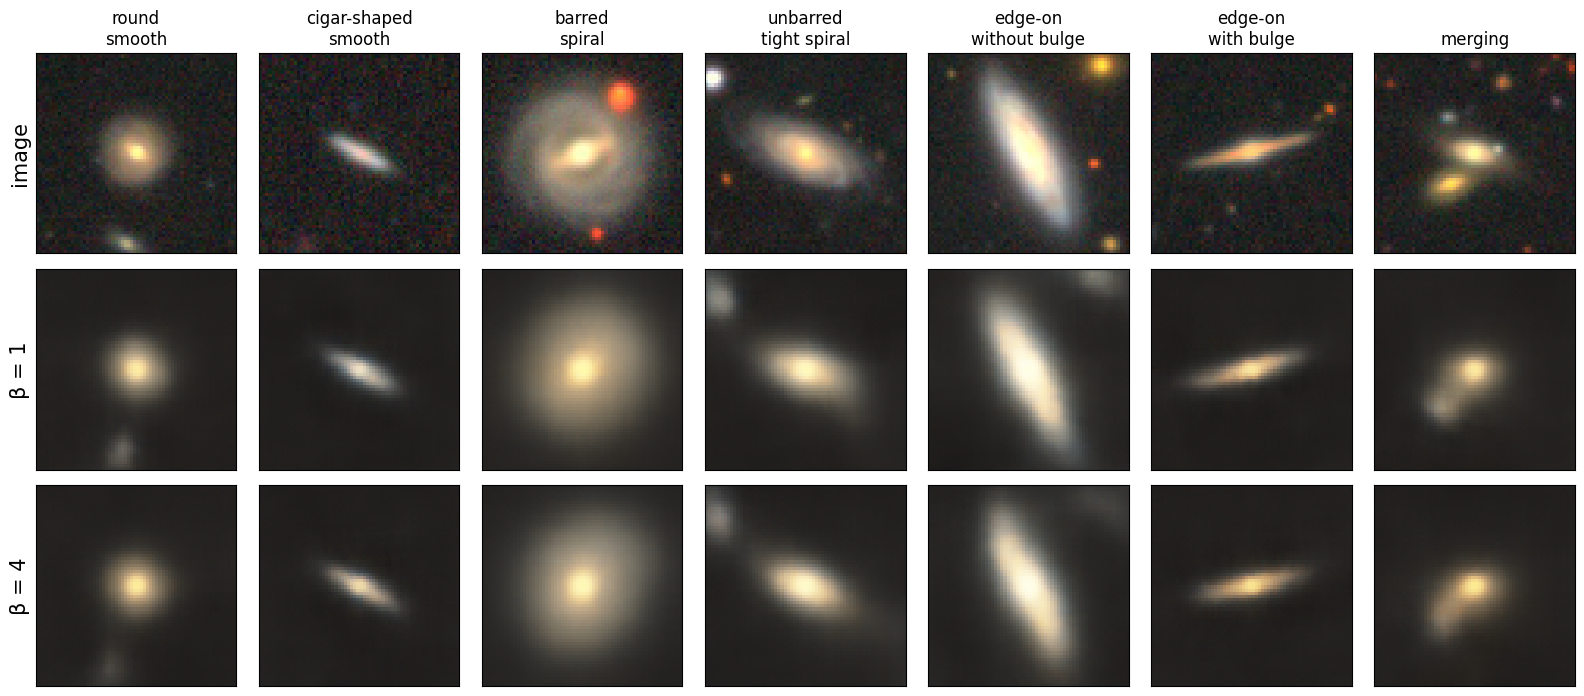

In [8]:
def encode(model, X, bs=500):
    with torch.no_grad():
        out = [model.encode(X[i:i + bs]) for i in range(0, len(X), bs)]
    return torch.cat([o[0] for o in out]), torch.cat([o[1] for o in out])
def decode(model, Z, bs=500):
    with torch.no_grad(): return torch.cat([model.decode(Z[i:i + bs]) for i in range(0, len(Z), bs)])

MU, KL, REC = {}, {}, {}
for key, m in vaes.items():
    mu, lv = encode(m, X_te); MU[key] = mu.numpy(); KL[key] = kl_per_coordinate(mu, lv).mean(0).numpy()
    REC[key] = decode(m, mu)
    rmse = float(((REC[key] - X_te) ** 2).mean().sqrt())
    nums[f"vae_beta{key[0]}_seed{key[1]}"] = dict(rmse=round(rmse, 4), kl=np.round(KL[key], 3).tolist(), kl_total=round(float(KL[key].sum()), 2))
    print(f"beta = {key[0]}, seed {key[1]}: test RMSE per pixel {rmse:.4f};  total KL {KL[key].sum():.1f} nats;  KL per coordinate {np.round(KL[key], 2)}")

show = [te_idx.tolist().index(i) for i in te_idx[[np.flatnonzero(G_lab[te_idx] == k)[0] for k in [2, 4, 5, 6, 8, 9, 1]]]]
fig, axs = plt.subplots(3, len(show), figsize=(2.3 * len(show), 7.2))
for j, i in enumerate(show):
    for r, (img, lab) in enumerate([(X_te[i], "image"), (REC[1, 0][i], "β = 1"), (REC[4, 0][i], "β = 4")]):
        axs[r, j].imshow(img.permute(1, 2, 0).numpy()); axs[r, j].set_xticks([]); axs[r, j].set_yticks([])
        if j == 0: axs[r, j].set_ylabel(lab)
    axs[0, j].set_title(CLASSES[G_lab[te_idx[i]]].replace(" ", "\n", 1), fontsize=12)
plt.tight_layout(); plt.show()

All three models reconstruct the test galaxies with a root-mean-square error of about 0.058 per pixel, on a scale from 0 to 1. The value of $\beta$ changes how much information the latent code carries rather than the reconstruction error: 37.2 nats per galaxy for $\beta=1$ against 26.3 and 27.2 nats for the two models with $\beta=4$. With ten coordinates and these budgets, every coordinate is used (between 1.9 and 4.0 nats each); the stronger KL weight spreads the information more unevenly over the coordinates but switches none of them off.

## Active coordinates and traversals

The average KL of coordinate $k$ over the test images, $\overline{\mathrm{KL}}_k$, measures how much information about the image that coordinate carries. A coordinate whose encoder output stays at $\mu_k\approx0$, $\sigma_k\approx1$ for every image has $\overline{\mathrm{KL}}_k\approx0$: the decoder ignores it. We call a coordinate active if $\overline{\mathrm{KL}}_k>0.1$ nats.

A traversal decodes
$$\mathbf x'(\delta)=G\big(\boldsymbol\mu(\mathbf x)+\delta\,\mathbf e_k\big) \tag{6}$$
for $\delta$ from $-3$ to $3$, three prior standard deviations on each side, keeping the other coordinates at the encoding of a real galaxy. Each row of the figure below is one active coordinate, ordered by $\overline{\mathrm{KL}}_k$, and the three blocks show three galaxies of different classes.

beta = 1, seed 0: 10 active coordinates, ordered by KL: ['z9', 'z8', 'z7', 'z10', 'z3', 'z4', 'z2', 'z5', 'z6', 'z1']
beta = 4, seed 0: 10 active coordinates, ordered by KL: ['z8', 'z5', 'z9', 'z7', 'z6', 'z4', 'z3', 'z10', 'z2', 'z1']
beta = 4, seed 1: 10 active coordinates, ordered by KL: ['z5', 'z8', 'z7', 'z1', 'z2', 'z10', 'z9', 'z4', 'z6', 'z3']


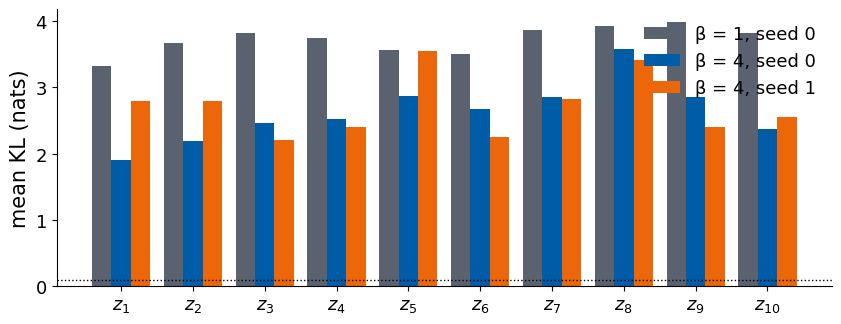

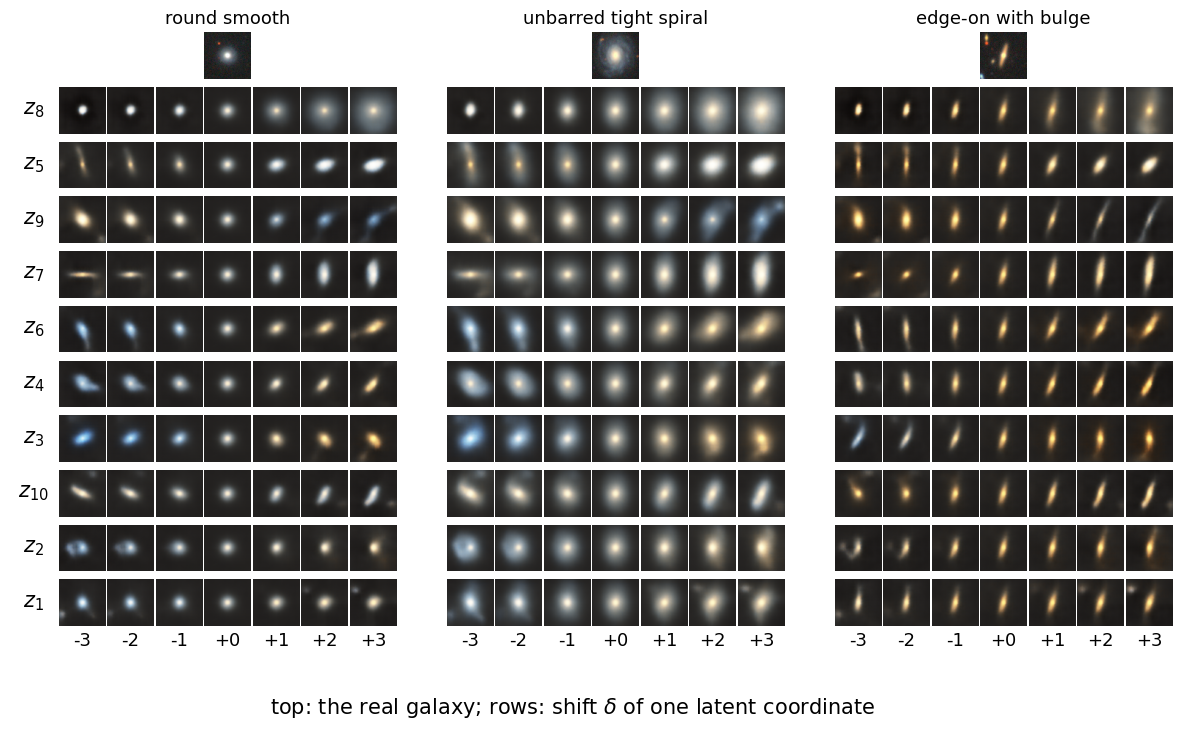

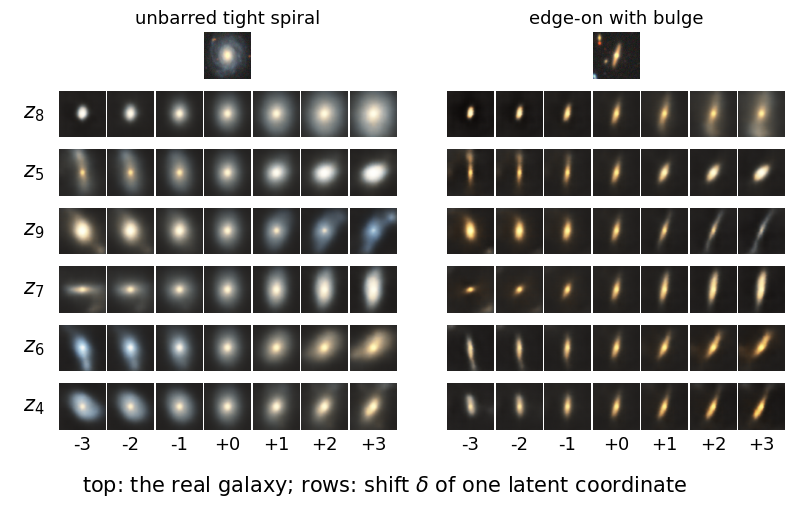

In [9]:
KL_ACTIVE = 0.1
active = {key: np.flatnonzero(KL[key] > KL_ACTIVE)[np.argsort(-KL[key][KL[key] > KL_ACTIVE])] for key in vaes}
for key in vaes: print(f"beta = {key[0]}, seed {key[1]}: {len(active[key])} active coordinates, ordered by KL: {[f'z{k + 1}' for k in active[key]]}")
nums["n_active"] = {f"beta{k[0]}_seed{k[1]}": int(len(v)) for k, v in active.items()}

fig, ax = plt.subplots(figsize=(10, 3.6))
for j, (key, col) in enumerate([((1, 0), gray), ((4, 0), blue), ((4, 1), orange)]):
    ax.bar(np.arange(10) + 0.27 * (j - 1), KL[key], width=0.27, color=col, label=f"β = {key[0]}, seed {key[1]}")
ax.axhline(KL_ACTIVE, color="k", ls=":", lw=1); ax.set_xticks(range(10)); ax.set_xticklabels([f"$z_{{{k + 1}}}$" for k in range(10)])
ax.set_ylabel("mean KL (nats)"); ax.legend(frameon=False); clean(ax); plt.show()

DELTAS = np.linspace(-3, 3, 7)
def traversal(model, mu, k, deltas=DELTAS):
    """Decoded images G(mu + delta e_k) for every delta; mu: (d,) tensor -> (len(deltas), 3, 64, 64)."""
    Z = mu[None].repeat(len(deltas), 1); Z[:, k] += torch.tensor(deltas, dtype=torch.float32)
    return decode(model, Z)

def traversal_figure(key, gal, fname=None, n_max=None):
    """Rows: the real galaxies, then one row per active coordinate (largest KL first); columns: delta from -3 to 3."""
    model, ks = vaes[key], active[key][:n_max]
    nd = len(DELTAS); ncol = 1 + (nd + 1) * len(gal) - 1; w = 10.0 if len(gal) < 3 else 15.0
    fig, axs = plt.subplots(len(ks) + 1, ncol, figsize=(w, w / ncol * (len(ks) + 1) + 0.9))
    for a in axs.ravel(): a.set_xticks([]); a.set_yticks([]); [sp.set_visible(False) for sp in a.spines.values()]
    for r, k in enumerate(ks):                                  # coordinate names in the first column
        axs[r + 1, 0].text(0.5, 0.5, f"$z_{{{k + 1}}}$", ha="center", va="center", fontsize=15, transform=axs[r + 1, 0].transAxes)
    for g_, i in enumerate(gal):
        c0_ = 1 + g_ * (nd + 1)                                 # first column of this galaxy's block
        mid = axs[0, c0_ + nd // 2]; mid.imshow(X_te[i].permute(1, 2, 0).numpy())
        mid.set_title(SHORT[G_lab[te_idx[i]]].replace("\n", " "), fontsize=13)
        mu = torch.tensor(MU[key][i])
        for r, k in enumerate(ks):
            for c, img in enumerate(traversal(model, mu, k)):
                a = axs[r + 1, c0_ + c]; a.imshow(img.permute(1, 2, 0).numpy())
                if r == len(ks) - 1: a.set_xlabel(f"{DELTAS[c]:+.0f}", fontsize=13)
    fig.text(0.5, 0.0, r"top: the real galaxy; rows: shift $\delta$ of one latent coordinate", ha="center", fontsize=15)
    plt.subplots_adjust(wspace=0.04, hspace=0.06)
    if fname: plt.savefig(f"{OUT}/{fname}", dpi=200, bbox_inches="tight")
    plt.show()

GAL = [int(np.flatnonzero(G_lab[te_idx] == k)[3]) for k in (2, 6, 9)]          # round smooth, tight spiral, edge-on with bulge
traversal_figure((4, 0), GAL)
traversal_figure((4, 0), GAL[1:], "interp_galaxy_traversals.png", n_max=6)    # slide: two galaxies, six coordinates

The traversals of the $\beta=4$ model show smooth, galaxy-like images in which one coordinate changes one visible property more than the others. Along $z_8$ the galaxy grows from a compact core to a large, bright disk; $z_7$ turns an elongated image between horizontal and vertical orientations; $z_9$, $z_6$ and $z_4$ rotate and stretch the image along the diagonals; along $z_5$ a face-on spiral becomes an elongated, edge-on-looking disk. None of the coordinates turns on spiral arms or a bar: at 64 pixels these details are largely lost in the reconstructions.

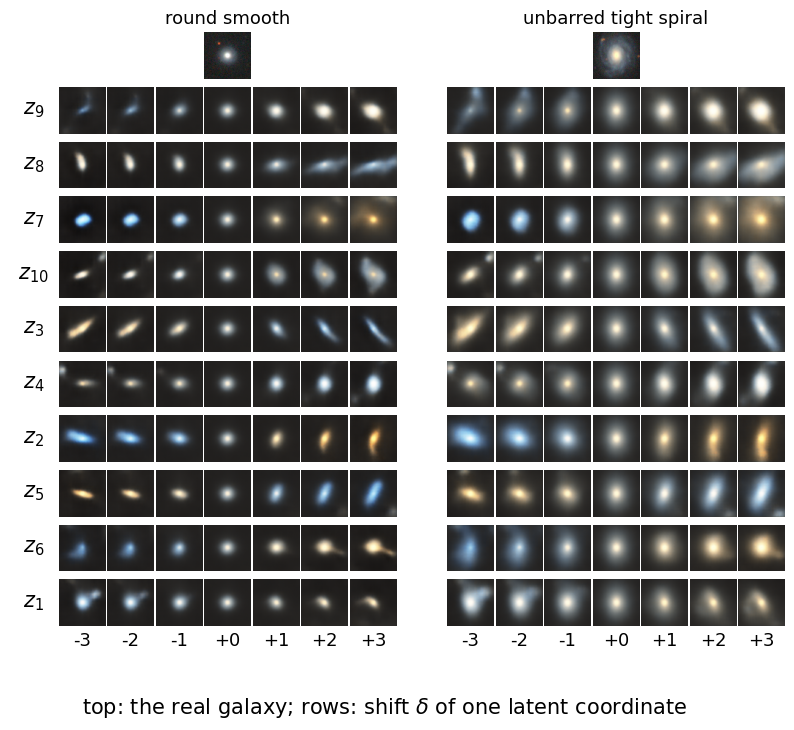

In [10]:
traversal_figure((1, 0), GAL[:2])

For the $\beta=1$ model most coordinates correlate with several proxies at once (next section), so a single row of its traversals rarely corresponds to one property: size, brightness and elongation change together.

## Latent coordinates and morphology proxies

The encoder means $\mu_k$ of the 2660 test galaxies are compared with the proxies measured from the same images, through the absolute Pearson correlation $|\mathrm{corr}(\mu_k,\text{proxy}_j)|$. We name a coordinate after a proxy only when the relation is clear: the largest correlation of the coordinate must be at least 0.5, and at least 0.15 larger than its correlation with any other proxy. Two pairs of proxies are related by construction (size and $r_{50}$; size and brightness), so these pairs are exempt from the second condition, and the name then lists both.

beta = 1, seed 0:
   z9  KL  3.98  size 0.50 brightness 0.54 r50 0.42 b/a 0.11 cos2θ 0.06 sin2θ 0.33 e1 0.09 e2 0.44 colour 0.09 C 0.16 offset 0.05   -> mixed
   z8  KL  3.92  size 0.55 brightness 0.58 r50 0.53 b/a 0.04 cos2θ 0.40 sin2θ 0.18 e1 0.51 e2 0.23 colour 0.10 C 0.16 offset 0.10   -> mixed
   z7  KL  3.86  size 0.57 brightness 0.61 r50 0.61 b/a 0.03 cos2θ 0.07 sin2θ 0.02 e1 0.10 e2 0.05 colour 0.20 C 0.12 offset 0.22   -> r50/brightness/size
   z10 KL  3.82  size 0.73 brightness 0.78 r50 0.73 b/a 0.00 cos2θ 0.17 sin2θ 0.19 e1 0.22 e2 0.25 colour 0.20 C 0.24 offset 0.14   -> brightness/size/r50
   z3  KL  3.82  size 0.16 brightness 0.16 r50 0.11 b/a 0.04 cos2θ 0.22 sin2θ 0.60 e1 0.28 e2 0.76 colour 0.09 C 0.05 offset 0.05   -> e2/sin2θ
   z4  KL  3.74  size 0.43 brightness 0.44 r50 0.36 b/a 0.10 cos2θ 0.32 sin2θ 0.26 e1 0.40 e2 0.34 colour 0.13 C 0.15 offset 0.06   -> mixed
   z2  KL  3.66  size 0.26 brightness 0.26 r50 0.22 b/a 0.11 cos2θ 0.43 sin2θ 0.24 e1 0.57 e2 0.32 colour

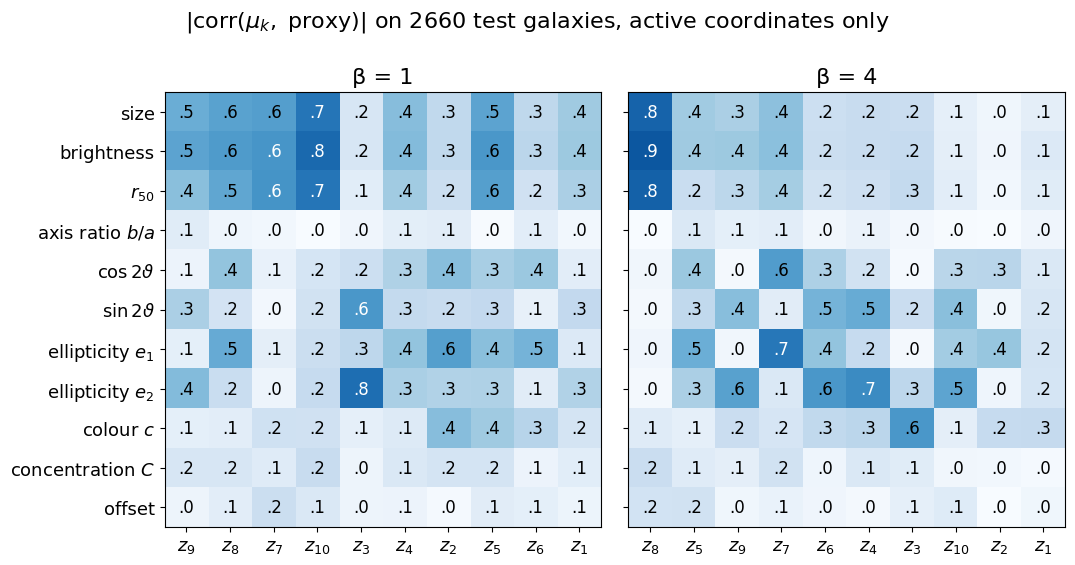

In [11]:
def abs_corr(Z, P):
    """|Pearson correlation| between every column of Z (n, d) and every column of P (n, J); rows with NaN dropped."""
    m = ~np.isnan(P).any(1); Z, P = Z[m], P[m]
    Zs = (Z - Z.mean(0)) / (Z.std(0) + 1e-12); Ps = (P - P.mean(0)) / (P.std(0) + 1e-12)
    return np.abs(Zs.T @ Ps / len(Z))

RELATED = [{"area", "r50"}, {"area", "flux"}, {"flux", "r50"}, {"e1", "cos2pa"}, {"e2", "sin2pa"}]
def name_coordinates(R, ks):
    names = {}
    for k in ks:
        o = np.argsort(-R[k]); top = PROXIES[o[0]]
        rivals = [j for j in o[1:] if {PROXIES[j], top} not in RELATED]
        if R[k, o[0]] >= 0.5 and R[k, o[0]] - R[k, rivals[0]] >= 0.15:
            partners = [PROXIES[j] for j in o[1:] if {PROXIES[j], top} in RELATED and R[k, j] >= 0.5]
            names[k] = "/".join(SHORTP[p] for p in [top] + partners)
        else:
            names[k] = "mixed"
    return names

R_corr, NAMES = {}, {}
for key in vaes:
    R_corr[key] = abs_corr(MU[key], P_te)
    NAMES[key] = name_coordinates(R_corr[key], active[key])
    print(f"beta = {key[0]}, seed {key[1]}:")
    for k in active[key]:
        print(f"   z{k + 1:<2d} KL {KL[key][k]:5.2f}  " + " ".join(f"{SHORTP[p]} {R_corr[key][k, j]:.2f}" for j, p in enumerate(PROXIES)) + f"   -> {NAMES[key][k]}")
    nums[f"corr_beta{key[0]}_seed{key[1]}"] = {f"z{k + 1}": dict(zip(PROXIES, np.round(R_corr[key][k], 3).tolist())) for k in active[key]}
    nums[f"names_beta{key[0]}_seed{key[1]}"] = {f"z{k + 1}": NAMES[key][k] for k in active[key]}

fig, axs = plt.subplots(1, 2, figsize=(11, 5.8), gridspec_kw={"width_ratios": [len(active[1, 0]) + 0.5, len(active[4, 0]) + 0.5]})
for a, key in zip(axs, [(1, 0), (4, 0)]):
    R = R_corr[key][active[key]].T
    a.imshow(R, cmap="Blues", vmin=0, vmax=1, aspect="auto")
    for i in range(R.shape[0]):
        for j in range(R.shape[1]):
            a.text(j, i, f"{R[i, j]:.1f}"[1:] if R[i, j] < 0.995 else "1", ha="center", va="center", fontsize=12, color="white" if R[i, j] > 0.6 else "black")
    a.set_xticks(range(R.shape[1])); a.set_xticklabels([f"$z_{{{k + 1}}}$" for k in active[key]])
    a.set_yticks(range(len(PROXIES))); a.set_yticklabels(PROXY_LABELS if key == (1, 0) else [], fontsize=13)
    a.set_title(f"β = {key[0]}", fontsize=16)
fig.suptitle(r"$|\mathrm{corr}(\mu_k,\ \mathrm{proxy})|$ on 2660 test galaxies, active coordinates only", fontsize=16)
plt.tight_layout(); plt.savefig(f"{OUT}/interp_galaxy_factor_matrix.png", dpi=200, bbox_inches="tight"); plt.show()

For $\beta=1$ the size and brightness of the galaxy are spread over several coordinates ($z_{10}$, $z_7$ and $z_5$ correlate with them at 0.54 to 0.78), the orientation over $z_3$ and others, and six of the ten coordinates are mixed. For $\beta=4$ the picture is cleaner: a single coordinate, $z_8$, follows brightness, size and half-light radius with correlations 0.85, 0.80 and 0.81 and hardly anything else; $z_7$ follows the horizontal-vertical elongation $e_1$ (0.72); $z_4$, $z_6$, $z_9$ and $z_{10}$ follow the diagonal elongation $e_2$ (0.54 to 0.65); and $z_3$ follows the colour (0.60). The axis ratio $b/a$, the concentration and the offset are not followed by any coordinate (all correlations below 0.3). Orientation and elongation appear combined, as the two components of the ellipticity, which is how a coordinate system that has to describe a rotating elongated object would naturally encode them.

## Stability across seeds

A factor found once may be an accident of the initialisation. We compare the two $\beta=4$ models trained with different seeds in two ways: for every proxy, the coordinate of each model that correlates best with it; and directly, the correlation $|\mathrm{corr}(\mu^{(0)}_k,\mu^{(1)}_l)|$ between the coordinates of the two models on the same test images. If both models found the same factors, each active coordinate of one has a partner in the other with a correlation close to 1, possibly with a different index and sign, since the prior does not distinguish the coordinates or their signs.

In [12]:
a0, a1 = active[4, 0], active[4, 1]
for j, p in enumerate(PROXIES):
    k0, k1 = a0[np.argmax(R_corr[4, 0][a0, j])], a1[np.argmax(R_corr[4, 1][a1, j])]
    print(f"{SHORTP[p]:11s} seed 0: z{k0 + 1:<2d} {R_corr[4, 0][k0, j]:.2f}    seed 1: z{k1 + 1:<2d} {R_corr[4, 1][k1, j]:.2f}")
cross = abs_corr(MU[4, 0][:, a0], MU[4, 1][:, a1])
best = cross.max(1)
for k, b, l in zip(a0, best, cross.argmax(1)):
    print(f"seed 0 z{k + 1:<2d} ({NAMES[4, 0][k]:>14s}) best partner in seed 1: z{a1[l] + 1:<2d} ({NAMES[4, 1][a1[l]]:>14s}), |corr| = {b:.2f}")
nums["seed_best_partner_corr"] = np.round(best, 3).tolist()
nums["seed_proxy_best"] = {p: [round(float(R_corr[4, 0][a0, j].max()), 3), round(float(R_corr[4, 1][a1, j].max()), 3)] for j, p in enumerate(PROXIES)}

size        seed 0: z8  0.80    seed 1: z5  0.80
brightness  seed 0: z8  0.85    seed 1: z5  0.83
r50         seed 0: z8  0.81    seed 1: z8  0.77
b/a         seed 0: z5  0.15    seed 1: z5  0.15
cos2θ       seed 0: z7  0.58    seed 1: z1  0.53
sin2θ       seed 0: z4  0.51    seed 1: z7  0.54
e1          seed 0: z7  0.72    seed 1: z1  0.67
e2          seed 0: z4  0.65    seed 1: z7  0.69
colour      seed 0: z3  0.60    seed 1: z4  0.61
C           seed 0: z8  0.23    seed 1: z5  0.29
offset      seed 0: z5  0.19    seed 1: z8  0.23
seed 0 z8  (brightness/r50/size) best partner in seed 1: z8  (brightness/r50/size), |corr| = 0.97
seed 0 z5  (         mixed) best partner in seed 1: z2  (         mixed), |corr| = 0.64
seed 0 z9  (            e2) best partner in seed 1: z7  (      e2/sin2θ), |corr| = 0.54
seed 0 z7  (      e1/cos2θ) best partner in seed 1: z5  (brightness/size/r50), |corr| = 0.71
seed 0 z6  (            e2) best partner in seed 1: z2  (         mixed), |corr| = 0.79
seed 0

Only one factor is found reproducibly. The brightness and size coordinate of the first model ($z_8$) has a partner in the second model ($z_8$ again) with a correlation of 0.97, and both models have a coordinate that follows the brightness with a correlation above 0.83. The elongation and colour factors also appear in both models with similar strength (best correlations 0.51 to 0.72 for $e_1$, $e_2$, $\cos2\vartheta$, $\sin2\vartheta$ and colour), but they are distributed differently over the coordinates: the best partners of the corresponding coordinates correlate only at 0.53 to 0.79. A coordinate named "colour" in one model has no single counterpart in the other. This is the instability that Locatello et al. warned about, and a reason not to name a latent coordinate after a physical property from a single trained model.

## Factors per galaxy class

The β-VAE never saw a label. Plotting the distribution of each active coordinate of the $\beta=4$ model separately for the ten classes shows which factors separate which classes.

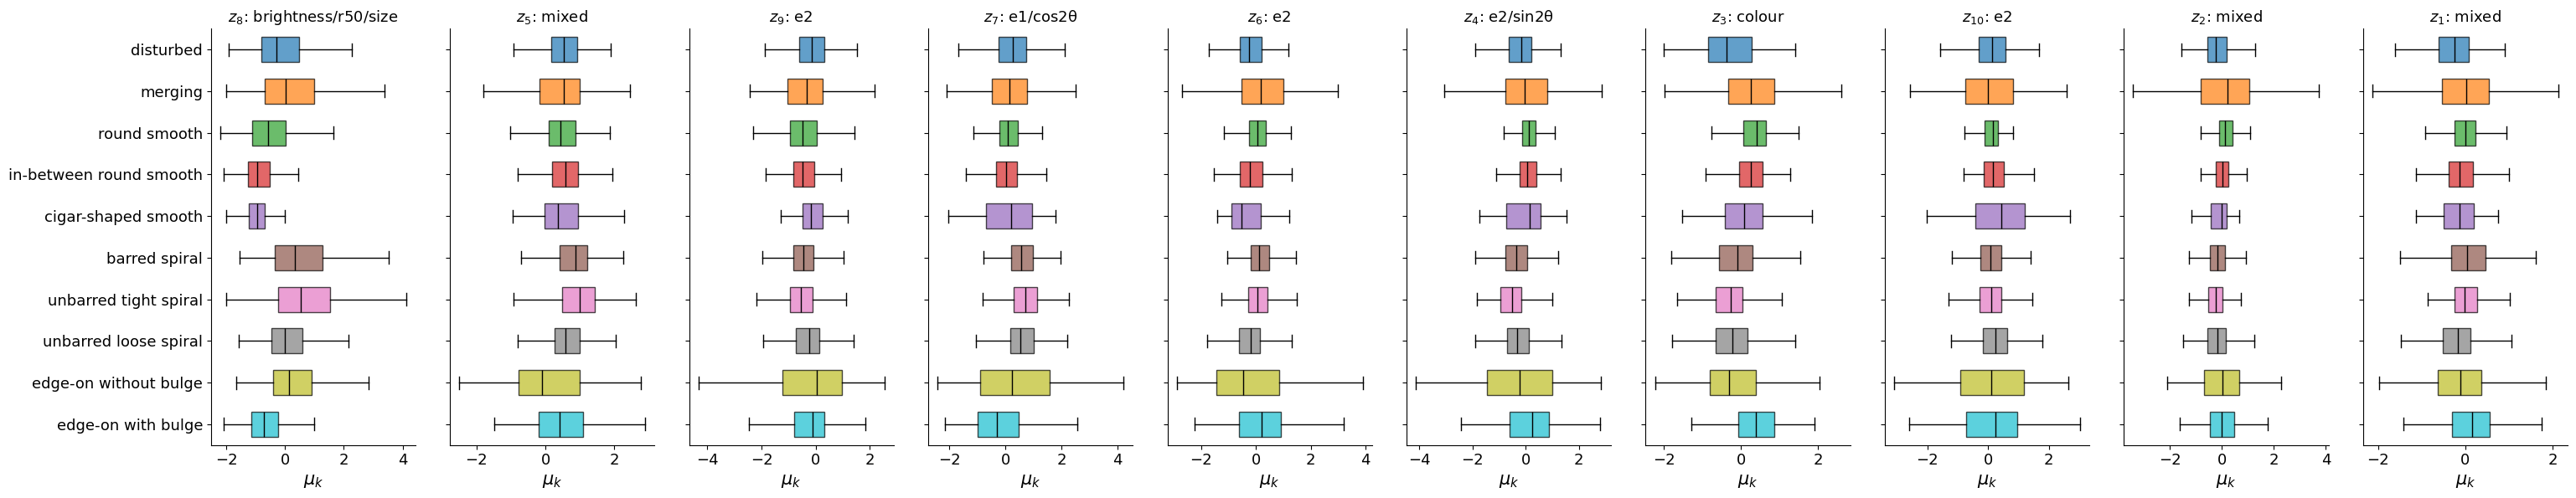

z8  (brightness/r50/size): class medians from in-between round smooth (-0.96) to unbarred tight spiral (+0.52); range / typical interquartile width = 1.2
z5  (         mixed): class medians from edge-on without bulge (-0.10) to unbarred tight spiral (+0.99); range / typical interquartile width = 1.3
z9  (            e2): class medians from unbarred tight spiral (-0.53) to edge-on without bulge (+0.05); range / typical interquartile width = 0.7
z7  (      e1/cos2θ): class medians from edge-on with bulge (-0.30) to unbarred tight spiral (+0.72); range / typical interquartile width = 1.1
z6  (            e2): class medians from cigar-shaped smooth (-0.54) to edge-on with bulge (+0.22); range / typical interquartile width = 0.9
z4  (      e2/sin2θ): class medians from unbarred tight spiral (-0.50) to edge-on with bulge (+0.23); range / typical interquartile width = 0.9
z3  (        colour): class medians from disturbed (-0.37) to round smooth (+0.42); range / typical interquartile width = 

In [13]:
key = (4, 0); ks = active[key]
fig, axs = plt.subplots(1, len(ks), figsize=(3.1 * len(ks), 6.2), sharey=True)
axs = np.atleast_1d(axs)
cols = plt.get_cmap("tab10")
for a, k in zip(axs, ks):
    data = [MU[key][G_lab[te_idx] == c, k] for c in range(10)]
    bp = a.boxplot(data, vert=False, widths=0.6, showfliers=False, patch_artist=True)
    for c, patch in enumerate(bp["boxes"]): patch.set_facecolor(cols(c)); patch.set_alpha(0.7)
    for med in bp["medians"]: med.set_color("k")
    a.set_title(f"$z_{{{k + 1}}}$: {NAMES[key][k]}", fontsize=13); a.set_xlabel(r"$\mu_k$"); clean(a)
axs[0].set_yticks(range(1, 11)); axs[0].set_yticklabels(CLASSES); axs[0].invert_yaxis()
plt.tight_layout(); plt.show()
sep = {}
for k in ks:                                            # separation: spread of the class medians over the typical width
    med = np.array([np.median(MU[key][G_lab[te_idx] == c, k]) for c in range(10)])
    iqr = np.median([np.subtract(*np.percentile(MU[key][G_lab[te_idx] == c, k], [75, 25])) for c in range(10)])
    sep[k] = (med.max() - med.min()) / iqr
    print(f"z{k + 1:<2d} ({NAMES[key][k]:>14s}): class medians from {CLASSES[med.argmin()]} ({med.min():+.2f}) to {CLASSES[med.argmax()]} ({med.max():+.2f}); "
          f"range / typical interquartile width = {sep[k]:.1f}")
nums["class_separation"] = {f"z{k + 1}": round(float(v), 2) for k, v in sep.items()}

The class medians of a single coordinate differ by about one interquartile width at most (ratio 0.5 to 1.3): no coordinate separates the classes on its own, and the classes overlap strongly in every direction of the latent space. The largest shifts are physically sensible. The brightness and size coordinate $z_8$ is lowest for in-between round smooth galaxies, compact and faint, and highest for unbarred tight spirals; the colour coordinate $z_3$ runs from disturbed galaxies, blue, to round smooth ones, red; and the elongation coordinate $z_6$ separates cigar-shaped smooth galaxies from edge-on disks with a bulge. The morphology is spread over combinations of coordinates rather than aligned with any one of them.

## Morphology classifier

The classifier whose decisions we want to explain is a convolutional neural network (CNN) with global average pooling, the design of Model E of Lecture 4. Four blocks of a $3\times3$ convolution, batch normalisation and ReLU, the first three followed by $2\times2$ max-pooling, take the $64\times64\times3$ image to $8\times8\times128$ feature maps; global average pooling turns every map into one number, and a dense layer gives the ten class scores, turned into probabilities $p_c(\mathbf x)$ by the softmax. The inputs are standardised with the channel means and standard deviations of the training images. Training uses the cross-entropy loss, Adam, random flips and random rotations by multiples of $90^\circ$, all of which leave the class of a galaxy unchanged.

epoch 4: test accuracy 0.605  (198 s)


epoch 8: test accuracy 0.714  (573 s)


epoch 12: test accuracy 0.764  (795 s)


test accuracy 0.764


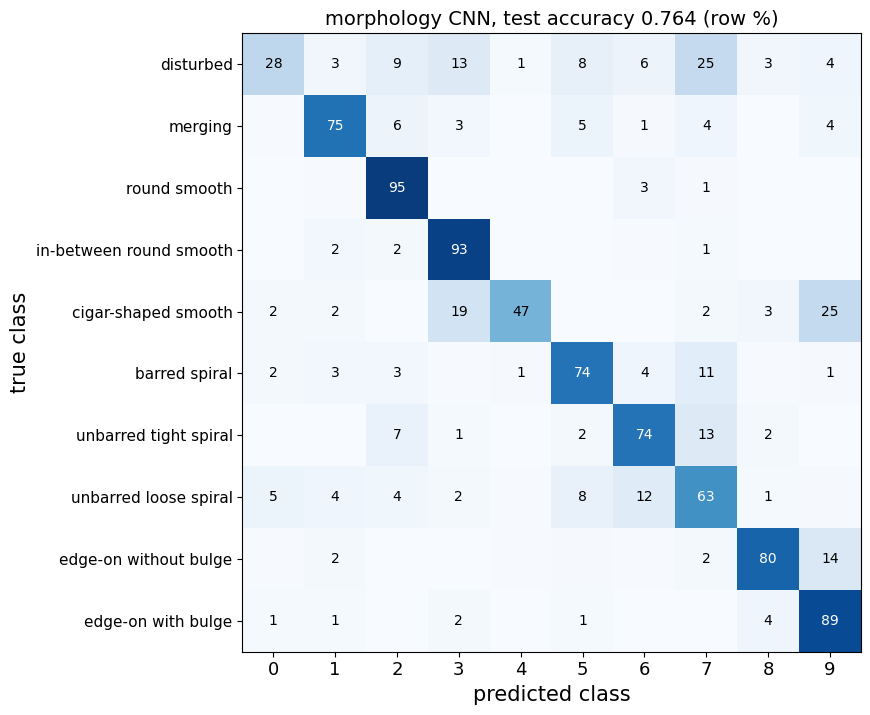

In [14]:
class GapCNN(nn.Module):
    def __init__(self, n_classes=10):
        super().__init__()
        def block(a, b, pool):
            layers = [nn.Conv2d(a, b, 3, padding=1), nn.BatchNorm2d(b), nn.ReLU()]
            return layers + [nn.MaxPool2d(2)] if pool else layers
        self.features = nn.Sequential(*block(3, 32, True), *block(32, 64, True), *block(64, 128, True), *block(128, 128, False))
        self.fc = nn.Linear(128, n_classes)
    def forward(self, x): return self.fc(self.features(x).mean(dim=(2, 3)))       # global average pooling

CH_MEAN, CH_STD = X_tr.mean((0, 2, 3)), X_tr.std((0, 2, 3))
norm = lambda x: (x - CH_MEAN[:, None, None]) / CH_STD[:, None, None]
def augment(x):
    x = random_flip(x); k = int(torch.randint(4, (1,))); return torch.rot90(x, k, (2, 3))
def probabilities(model, X, bs=500):
    with torch.no_grad(): return torch.cat([model(norm(X[i:i + bs])).softmax(1) for i in range(0, len(X), bs)]).numpy()

EPOCHS_CNN = 12
path = f"{RES}/interp_galaxy_classifier.pt"
seed(5); clf = GapCNN()
if os.path.exists(path):
    clf.load_state_dict(torch.load(path, map_location="cpu")); print("loaded", path)
else:
    opt = torch.optim.Adam(clf.parameters(), 1e-3); sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, EPOCHS_CNN); t0 = time.time()
    for ep in range(EPOCHS_CNN):
        clf.train(); perm = torch.randperm(len(X_tr))
        for i in range(0, len(perm), 128):
            j = perm[i:i + 128]; loss = F.cross_entropy(clf(norm(augment(X_tr[j]))), y_tr[j])
            opt.zero_grad(); loss.backward(); opt.step()
        sched.step(); clf.eval()
        if ep % 4 == 3: print(f"epoch {ep + 1}: test accuracy {(probabilities(clf, X_te).argmax(1) == y_te.numpy()).mean():.3f}  ({time.time() - t0:.0f} s)")
    torch.save(clf.state_dict(), path)
clf.eval()
p_real = probabilities(clf, X_te); pred_real = p_real.argmax(1)
acc = float((pred_real == y_te.numpy()).mean()); nums["clf_test_acc"] = acc
cm = np.zeros((10, 10))
for t, p in zip(y_te.numpy(), pred_real): cm[t, p] += 1
cm = cm / cm.sum(1, keepdims=True); np.save(f"{RES}/interp_galaxy_confusion.npy", cm)
nums["clf_recall_per_class"] = np.round(np.diag(cm), 3).tolist()
print(f"test accuracy {acc:.3f}")
fig, ax = plt.subplots(figsize=(8.6, 7.4))
ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
for i in range(10):
    for j in range(10):
        if cm[i, j] >= 0.01: ax.text(j, i, f"{100 * cm[i, j]:.0f}", ha="center", va="center", fontsize=10, color="white" if cm[i, j] > 0.5 else "black")
ax.set_xticks(range(10)); ax.set_yticks(range(10)); ax.set_yticklabels(CLASSES, fontsize=11); ax.set_xticklabels(range(10))
ax.set_xlabel("predicted class"); ax.set_ylabel("true class"); ax.set_title(f"morphology CNN, test accuracy {acc:.3f} (row %)", fontsize=14)
plt.tight_layout(); plt.show()

After 12 epochs the classifier reaches a test accuracy of 0.764 on the ten classes, with steady progress over the epochs (0.605 after 4, 0.714 after 8). This is the classifier whose decisions the counterfactuals are meant to explain.

## Counterfactuals through the latent space

The classifier was trained on real images, while a counterfactual, the decoded image of equation (6), is not a real image, and decoded images are smoother than real ones. Before reading any change of the prediction as a statement about the galaxy, we must know how the classifier treats plain reconstructions $G(\boldsymbol\mu(\mathbf x))$, with $\delta=0$. If they were classified very differently from the originals, every counterfactual would mostly measure the difference between real and decoded images.

In [15]:
real_conf = p_real.max(1)
for key in [(1, 0), (4, 0)]:
    p_rec = probabilities(clf, REC[key])
    agree = float((p_rec.argmax(1) == pred_real).mean()); acc_rec = float((p_rec.argmax(1) == y_te.numpy()).mean())
    nums[f"recon_beta{key[0]}"] = dict(acc=round(acc_rec, 3), agree_with_real=round(agree, 3), median_conf=round(float(np.median(p_rec.max(1))), 3))
    print(f"beta = {key[0]}: accuracy on reconstructions {acc_rec:.3f} (real images {acc:.3f}); same class as for the real image: {agree:.3f}; "
          f"median confidence {np.median(p_rec.max(1)):.3f} (real images {np.median(real_conf):.3f})")
    if key == (4, 0): p_rec4 = p_rec
nums["real_median_conf"] = round(float(np.median(real_conf)), 3)

beta = 1: accuracy on reconstructions 0.389 (real images 0.764); same class as for the real image: 0.419; median confidence 0.623 (real images 0.762)


beta = 4: accuracy on reconstructions 0.396 (real images 0.764); same class as for the real image: 0.424; median confidence 0.619 (real images 0.762)


The reconstructions are not faithful enough for the classifier. On decoded images its accuracy drops from 0.764 to 0.389 for $\beta=1$ and 0.396 for $\beta=4$, and only 42% of the reconstructions receive the same class as the real image; the median confidence falls from 0.76 to 0.62. The smooth, blurred reconstructions lack exactly the fine structure (arms, bars, irregularities) that distinguishes many of the classes. The sensitivity analysis is therefore restricted to galaxies whose reconstruction is classified like the real image, and its results describe how the classifier reacts to latent shifts of such decoded images, not of real galaxies.

For 400 test galaxies, 40 of each class, every active coordinate of the $\beta=4$ model is traversed with 13 values of $\delta$ from $-3$ to $3$, and the ten class probabilities are recorded. Let $c_0$ be the class predicted for the reconstruction at $\delta=0$. For coordinate $k$ we measure the sensitivity
$$
S_k=\Big\langle\max_{\delta}\big|p_{c_0}\big(\mathbf x'(\delta)\big)-p_{c_0}\big(\mathbf x'(0)\big)\big|\Big\rangle_{\text{galaxies}},
\tag{7}$$
the largest change of the probability of the original prediction along the traversal, averaged over galaxies, as equation (7), and the flip rate, the fraction of galaxies for which the predicted class changes somewhere in $|\delta|\le3$, together with the smallest $|\delta|$ at which this happens.

In [16]:
key = (4, 0); model = vaes[key]; ks = active[key]
DCF = np.linspace(-3, 3, 13)
rng = seed(11)
faithful = probabilities(clf, REC[key]).argmax(1) == pred_real               # reconstruction classified like the real image
cf_idx = np.concatenate([rng.permutation(np.flatnonzero((G_lab[te_idx] == c) & faithful))[:30] for c in range(10)])
nums["cf_n_per_class"] = [int(((G_lab[te_idx] == c) & faithful).sum()) for c in range(10)]
print("faithful reconstructions per class:", nums["cf_n_per_class"], "-> galaxies used:", len(cf_idx))
t0 = time.time()
PROB = np.zeros((len(cf_idx), len(ks), len(DCF), 10), np.float32)
for n, i in enumerate(cf_idx):
    mu = torch.tensor(MU[key][i]); Z = mu[None].repeat(len(ks) * len(DCF), 1)
    for r, k in enumerate(ks): Z[r * len(DCF):(r + 1) * len(DCF), k] += torch.tensor(DCF, dtype=torch.float32)
    PROB[n] = probabilities(clf, decode(model, Z)).reshape(len(ks), len(DCF), 10)
print(f"{len(cf_idx)} galaxies x {len(ks)} coordinates x {len(DCF)} shifts classified in {time.time() - t0:.0f} s")
i0 = int(np.argmin(np.abs(DCF)))
c0 = PROB[:, 0, i0].argmax(1)                                    # prediction on the reconstruction, delta = 0
p0 = PROB[np.arange(len(cf_idx)), :, :, c0]                      # (galaxies, coordinates, shifts): probability of c0
sens = np.abs(p0 - p0[:, :, i0:i0 + 1]).max(2)                   # largest change of p_c0 along the traversal
flips = (PROB.argmax(3) != c0[:, None, None])                    # (galaxies, coordinates, shifts)
flip_rate = flips.any(2).mean(0)
dmin = np.where(flips, np.abs(DCF)[None, None, :], np.inf).min(2)  # smallest |delta| with a changed prediction
order = np.argsort(-sens.mean(0))
print("coordinate  name            sensitivity  flip rate  median |delta| at flip")
for r in order:
    md_ = np.median(dmin[:, r][np.isfinite(dmin[:, r])]) if np.isfinite(dmin[:, r]).any() else np.nan
    print(f"z{ks[r] + 1:<10d} {NAMES[key][ks[r]]:>22s}   {sens[:, r].mean():.3f}       {flip_rate[r]:.3f}      {md_:.1f}")
nums["sensitivity"] = {f"z{ks[r] + 1}": dict(name=NAMES[key][ks[r]], S=round(float(sens[:, r].mean()), 3), flip_rate=round(float(flip_rate[r]), 3)) for r in order}
# where do the flips go? for each coordinate, the most frequent (from -> to) class pairs
for r in order[:3]:
    pairs = {}
    for n in range(len(cf_idx)):
        if flips[n, r].any():
            j = np.flatnonzero(flips[n, r]); j = j[np.argmin(np.abs(DCF[j]))]
            to = int(PROB[n, r, j].argmax()); pairs[(int(c0[n]), to)] = pairs.get((int(c0[n]), to), 0) + 1
    top = sorted(pairs.items(), key=lambda t: -t[1])[:4]
    print(f"z{ks[r] + 1} most frequent flips:", "; ".join(f"{CLASSES[a]} -> {CLASSES[b]}: {m}" for (a, b), m in top))
    nums[f"flips_z{ks[r] + 1}"] = [[CLASSES[a], CLASSES[b], m] for (a, b), m in top]

faithful reconstructions per class: [29, 85, 278, 97, 14, 16, 168, 55, 176, 211] -> galaxies used: 269


269 galaxies x 10 coordinates x 13 shifts classified in 48 s
coordinate  name            sensitivity  flip rate  median |delta| at flip
z5                           mixed   0.595       0.933      1.0
z7                        e1/cos2θ   0.593       0.914      1.0
z3                          colour   0.585       0.926      1.0
z9                              e2   0.579       0.907      1.0
z4                        e2/sin2θ   0.542       0.862      1.0
z2                           mixed   0.522       0.844      1.5
z6                              e2   0.518       0.788      1.0
z8             brightness/r50/size   0.503       0.840      1.0
z10                             e2   0.500       0.781      1.0
z1                           mixed   0.362       0.595      1.5
z5 most frequent flips: unbarred tight spiral -> edge-on without bulge: 49; edge-on without bulge -> unbarred tight spiral: 18; round smooth -> unbarred tight spiral: 18; round smooth -> in-between round smooth: 15
z7 most f

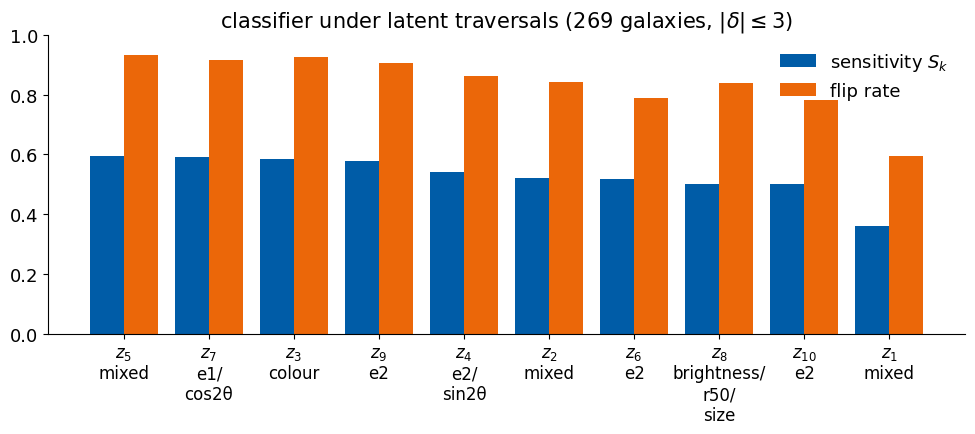

In [17]:
fig, ax = plt.subplots(figsize=(10, 4.6))
xs = np.arange(len(order))
ax.bar(xs - 0.2, sens.mean(0)[order], width=0.4, color=blue, label=r"sensitivity $S_k$")
ax.bar(xs + 0.2, flip_rate[order], width=0.4, color=orange, label="flip rate")
ax.set_xticks(xs); ax.set_xticklabels([f"$z_{{{ks[r] + 1}}}$\n{NAMES[key][ks[r]].replace('_', ' ').replace('/', '/\n')}" for r in order], fontsize=12)
ax.set_ylim(0, 1); ax.legend(frameon=False, loc="upper right"); clean(ax)
ax.set_title(f"classifier under latent traversals ({len(cf_idx)} galaxies, $|\\delta|\\leq3$)", fontsize=15)
plt.tight_layout(); plt.savefig(f"{OUT}/interp_galaxy_sensitivity.png", dpi=200, bbox_inches="tight"); plt.show()

Of the 2660 test galaxies, 1129 have a faithful reconstruction, unevenly spread over the classes: 278 round smooth galaxies and 211 edge-on galaxies with a bulge qualify, but only 14 cigar-shaped smooth galaxies and 16 barred spirals. At most 30 per class are used, 269 galaxies in total. Along every coordinate the predicted class changes for most of these galaxies (flip rates 0.60 to 0.93), typically already at $|\delta|=1$, one prior standard deviation. The sensitivities are similar for all coordinates (0.36 to 0.60), so no single factor dominates the decisions. The most frequent flips connect classes that share a geometric property: unbarred tight spirals become edge-on disks without a bulge (49 times along $z_5$ and along $z_7$), round smooth galaxies become tight spirals, and the two edge-on classes turn into each other. The classifier thus reacts strongly to the elongation and orientation of decoded images; whether it does so for real galaxies cannot be concluded from decoded images alone.

### One counterfactual

We pick one galaxy whose predicted class changes along a traversal and show the decoded images together with the probabilities of the original and the new class. Among all flips we prefer a face-on spiral that becomes an edge-on disk, a change an astronomer would recognise as a change of inclination; if there is none, the strongest flip of the most sensitive coordinate is shown.

galaxy 10531 (true class: unbarred tight spiral), real image predicted unbarred tight spiral, reconstruction predicted unbarred tight spiral; coordinate z5 (mixed) flips it to edge-on without bulge at delta = -2.0
axis ratio of the decoded images along the traversal: [np.float64(0.37), np.float64(0.62), np.float64(0.72), np.float64(0.89), np.float64(0.92), np.float64(0.81), np.float64(0.73)]
colour of the decoded images along the traversal:    [np.float32(-0.06), np.float32(-0.09), np.float32(-0.11), np.float32(-0.14), np.float32(-0.13), np.float32(-0.11), np.float32(-0.09)]


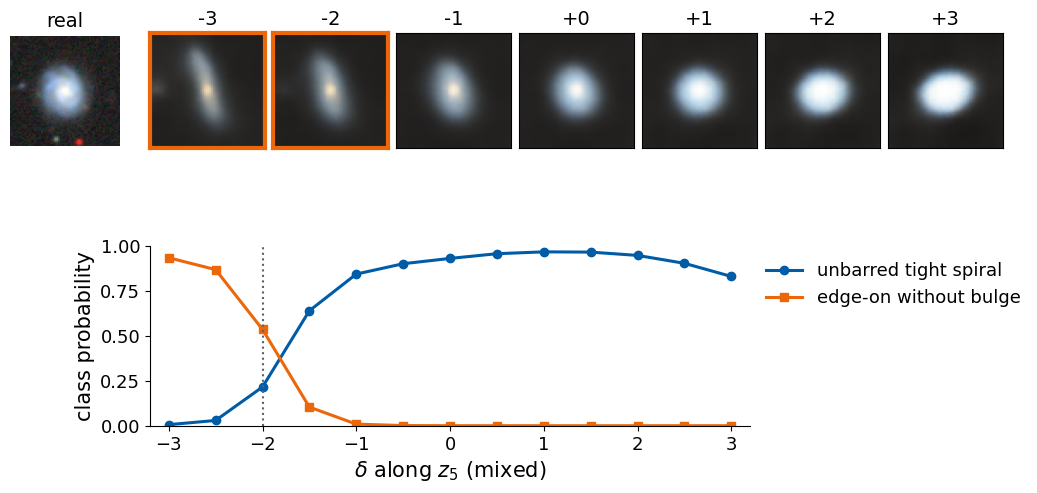

In [18]:
SPIRALS, EDGE = {5, 6, 7}, {8, 9}
cands = []
for n in range(len(cf_idx)):
    for r in range(len(ks)):
        if flips[n, r].any():
            j = np.flatnonzero(flips[n, r]); j = j[np.argmin(np.abs(DCF[j]))]; to = int(PROB[n, r, j].argmax())
            pref = (int(c0[n]) in SPIRALS and to in EDGE) + 0.5 * (int(c0[n]) == G_lab[te_idx[cf_idx[n]]])
            cands.append((pref, sens[n, r], n, r, to, DCF[j]))
cands.sort(key=lambda t: (-t[0], -t[1]))
if not cands:                                   # no flip at all: show the largest change along the most sensitive coordinate
    n, r = np.unravel_index(np.argmax(sens), sens.shape); j = np.argmax(np.abs(p0[n, r] - p0[n, r, i0]))
    second = PROB[n, r, j].argsort()[-2] if PROB[n, r, j].argmax() == c0[n] else PROB[n, r, j].argmax()
    cands = [(0, 0, n, r, int(second), DCF[j])]
pref, _, n, r, to, d_flip = cands[0]
i = cf_idx[n]; k = ks[r]
print(f"galaxy {te_idx[i]} (true class: {CLASSES[G_lab[te_idx[i]]]}), real image predicted {CLASSES[pred_real[i]]}, "
      f"reconstruction predicted {CLASSES[c0[n]]}; coordinate z{k + 1} ({NAMES[key][k]}) flips it to {CLASSES[to]} at delta = {d_flip:+.1f}")
nums["example_cf"] = dict(true=CLASSES[G_lab[te_idx[i]]], c0=CLASSES[int(c0[n])], to=CLASSES[to], coordinate=f"z{k + 1}", name=NAMES[key][k], delta=float(d_flip))
imgs = traversal(model, torch.tensor(MU[key][i]), k, DCF[::2])
props = [galaxy_proxies((im.permute(1, 2, 0).numpy() * 255).astype(np.uint8))[0] for im in imgs]
print("axis ratio of the decoded images along the traversal:", [round(p["axis_ratio"], 2) if p else None for p in props])
print("colour of the decoded images along the traversal:   ", [round(p["colour"], 2) if p else None for p in props])
nums["example_cf_axis_ratio"] = [round(float(p["axis_ratio"]), 3) if p else None for p in props]

fig = plt.figure(figsize=(10, 5.0))
a = fig.add_axes([0.0, 0.52, 0.11, 0.4]); a.imshow(X_te[i].permute(1, 2, 0).numpy()); a.axis("off"); a.set_title("real", fontsize=14)
for c, (img, dl) in enumerate(zip(imgs, DCF[::2])):
    a = fig.add_axes([0.14 + 0.123 * c, 0.52, 0.115, 0.4]); a.imshow(img.permute(1, 2, 0).numpy()); a.set_xticks([]); a.set_yticks([])
    a.set_title(f"{dl:+.0f}", fontsize=14)
    if (dl - d_flip) * np.sign(d_flip) >= 0 and dl * np.sign(d_flip) > 0:
        for s_ in a.spines.values(): s_.set_color(orange); s_.set_linewidth(3)
ax = fig.add_axes([0.14, 0.05, 0.6, 0.36])
ax.plot(DCF, PROB[n, r, :, c0[n]], "o-", color=blue, lw=2.2, label=CLASSES[c0[n]])
ax.plot(DCF, PROB[n, r, :, to], "s-", color=orange, lw=2.2, label=CLASSES[to])
ax.axvline(d_flip, color=gray, ls=":", lw=1.5); ax.set_ylim(0, 1); ax.set_xlim(-3.2, 3.2)
ax.set_xlabel(f"$\\delta$ along $z_{{{k + 1}}}$ ({NAMES[key][k]})"); ax.set_ylabel("class probability"); clean(ax)
ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(1.0, 1.0))
plt.savefig(f"{OUT}/interp_galaxy_counterfactual.png", dpi=200, bbox_inches="tight"); plt.show()

Along $z_5$ the face-on spiral becomes elongated as $\delta$ decreases: the axis ratio of the decoded image falls from 0.89 at $\delta=0$ to 0.37 at $\delta=-3$, while its colour hardly changes. At $\delta=-2$ the probability of "edge-on without bulge" overtakes that of "unbarred tight spiral". The classifier responds to the elongation, as an astronomer would when a disk is tilted towards edge-on. The decoded images, however, have lost the spiral arms already at $\delta=0$, so the example shows what the classifier does with the elongation of a smooth blob, not that it recognises spiral structure.

## Limits

Every statement above is conditional on a particular model. [Locatello et al. (ICML 2019)](https://proceedings.mlr.press/v97/locatello19a.html) ([arXiv:1811.12359](https://arxiv.org/abs/1811.12359)) proved that unsupervised learning of disentangled representations is impossible without inductive biases on both the models and the data: for a factorised prior there are infinitely many transformations of the latent space that mix the coordinates and yet leave the distribution of the data unchanged, so the likelihood cannot prefer the disentangled solution. In more than 12 000 trained models they found that the methods do enforce the properties their losses encourage, but that well-disentangled models could not be identified without supervision. For galaxies there is no supervision of this kind; the proxies play its role only partially, since they are themselves crude measurements from display-stretched images.

Three further limits are specific to the counterfactual technique. The decoded images are smoother than real ones, so the classifier sees a slightly different kind of input even at $\delta=0$, as measured above. Large shifts $|\delta|$ lead into regions of the latent space where few training galaxies lie, and the decoded image can be unlike any real galaxy; the classifier then answers a question about an unrealistic input. And at 64 pixels with ten latent coordinates, fine structure such as bars and the winding of spiral arms is largely blurred out, so factors that a human uses for some classes are simply not available as latent directions.

In summary, a $\beta$-VAE trained on galaxy images without labels finds one robust factor, the brightness and size of the galaxy, which appears with a correlation of 0.97 in two independent trainings. Elongation, orientation and colour are also encoded, but distributed differently over the coordinates from one training to the next. The morphology classes are not aligned with single coordinates, and the reconstructions are too blurred for the classifier, so counterfactual explanations through this latent space are limited to galaxies with faithful reconstructions and to properties that survive at 64 pixels. Interpretable latent factors are therefore a hypothesis to be tested, against measured proxies and across seeds, not something a $\beta$-VAE delivers by construction.

In [19]:
nums["runtime_s"] = round(time.time() - t_start)
json.dump(nums, open(f"{RES}/numbers_interpretability_galaxies.json", "w"), indent=1)
print(f"numbers saved; total run time {nums['runtime_s']} s")

numbers saved; total run time 2871 s


## References

- I. Higgins, L. Matthey, A. Pal, C. Burgess, X. Glorot, M. Botvinick, S. Mohamed, A. Lerchner, β-VAE: Learning basic visual concepts with a constrained variational framework, ICLR 2017, [openreview.net/forum?id=Sy2fzU9gl](https://openreview.net/forum?id=Sy2fzU9gl).
- C. P. Burgess, I. Higgins, A. Pal, L. Matthey, N. Watters, G. Desjardins, A. Lerchner, Understanding disentangling in β-VAE, [arXiv:1804.03599](https://arxiv.org/abs/1804.03599) (2018).
- F. Locatello, S. Bauer, M. Lucic, G. Rätsch, S. Gelly, B. Schölkopf, O. Bachem, Challenging common assumptions in the unsupervised learning of disentangled representations, ICML 2019, PMLR 97, 4114–4124, [arXiv:1811.12359](https://arxiv.org/abs/1811.12359).
- H. W. Leung, J. Bovy, Galaxy10 DECaLS, Zenodo (2024), [doi:10.5281/zenodo.10845026](https://doi.org/10.5281/zenodo.10845026), CC BY 4.0; documentation at [astronn.readthedocs.io](https://astronn.readthedocs.io/en/latest/galaxy10.html).
- M. Walmsley et al., Galaxy Zoo DECaLS: Detailed visual morphology measurements from volunteers and deep learning for 314 000 galaxies, MNRAS 509, 3966 (2022), [doi:10.1093/mnras/stab2093](https://doi.org/10.1093/mnras/stab2093).
- A. Dey et al., Overview of the DESI Legacy Imaging Surveys, AJ 157, 168 (2019), [doi:10.3847/1538-3881/ab089d](https://doi.org/10.3847/1538-3881/ab089d).
- C. J. Lintott et al., Galaxy Zoo: morphologies derived from visual inspection of galaxies from the Sloan Digital Sky Survey, MNRAS 389, 1179 (2008), [doi:10.1111/j.1365-2966.2008.13689.x](https://doi.org/10.1111/j.1365-2966.2008.13689.x).